# 05. Estudo de Hiperparâmetros e Busca Final

**DCT1401 — Inteligência Artificial (UFRN, 2026.2)**
**Aluna:** Mariana dos Santos Batista Medeiros (Matrícula: 20230083988)

**Atividade 03 — Redes Neurais Artificiais com PyTorch: Classificação e Regressão**

Este notebook investiga como cada hiperparâmetro da rede MLP afeta o desempenho, a generalização e o custo de treinamento, nos dois problemas: regressão de `Risk_Score` e classificação de `Cardiovascular_Disease`.

O estudo parte da configuração de referência (*baseline*) dos Notebooks 03 e 04 e varia **um hiperparâmetro por vez**, mantendo os demais fixos. Em seguida, examina a interação entre dois hiperparâmetros por meio de um mapa de calor e realiza uma busca aleatória para escolher a configuração final de cada problema.

Todas as decisões usam o subconjunto de validação. O CSV original é lido por inteiro para reproduzir a divisão. As linhas de teste são lidas apenas na conferência da divisão (contagem de registros, positivos e valores ausentes) e **não participam de nenhum ajuste, transformação, seleção ou avaliação neste notebook**; em seguida, são removidas da memória.

**Configuração do ambiente — Google Colab**

Esta etapa conecta o Google Colab ao Google Drive e configura os caminhos necessários para acessar o dataset original e os módulos Python do projeto.

A execução pressupõe que a pasta `projeto-cardiovascular-ia-03` esteja localizada em `Meu Drive`, conforme as instruções disponíveis no `README.md` da Atividade 03.

In [3]:
from google.colab import drive
from pathlib import Path
import importlib
import os
import sys

# 1. Conectar o Google Drive ao Colab
drive.mount("/content/drive")

# 2. Identificar a pasta principal do projeto
PROJETO = Path("/content/drive/MyDrive/projeto-cardiovascular-ia-03")

# 3. Verificar o dataset original e os módulos do projeto
ARQUIVO_RAW = PROJETO / "data/raw/cardiovascular_disease_prediction.csv"
assert ARQUIVO_RAW.is_file(), f"Dataset original não encontrado: {ARQUIVO_RAW}"

for modulo in ["__init__.py", "pipeline_data.py", "models.py", "train.py", "metrics.py", "visualization.py"]:
    assert (PROJETO / "src" / modulo).is_file(), f"Módulo ausente em src/: {modulo}"

# 4. Definir a pasta notebooks como diretório de execução
os.chdir(PROJETO / "notebooks")

# 5. Permitir a importação dos módulos da pasta src
if str(PROJETO) not in sys.path:
    sys.path.insert(0, str(PROJETO))

import src.pipeline_data as pipeline_data
import src.models as modelos_mlp
import src.metrics as metricas
import src.train as treino
import src.visualization as visualizacao

# Recarrega os módulos, caso uma versão anterior esteja em memória
for modulo in (pipeline_data, modelos_mlp, metricas, treino, visualizacao):
    importlib.reload(modulo)

# 6. Pastas e arquivos de saída
pasta_tabelas = PROJETO / "reports" / "tables"
pasta_figuras = PROJETO / "reports" / "figures"
pasta_logs = PROJETO / "logs"
pasta_curvas = pasta_logs / "curvas_estudo"
for pasta in (pasta_tabelas, pasta_figuras, pasta_curvas):
    pasta.mkdir(parents=True, exist_ok=True)

CAMINHO_LOG = pasta_logs / "hiperparametros.csv"

print("Projeto localizado em:", PROJETO)
print("Log do estudo:", CAMINHO_LOG.relative_to(PROJETO),
      "(existente)" if CAMINHO_LOG.is_file() else "(será criado)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Projeto localizado em: /content/drive/MyDrive/projeto-cardiovascular-ia-03
Log do estudo: logs/hiperparametros.csv (existente)


### Registro do ambiente de execução

Todo o estudo é executado em **CPU**. O tempo de treinamento é uma das colunas registradas para cada configuração, e ele só é comparável entre configurações executadas no mesmo hardware. Como sessões diferentes do Colab podem alocar processadores diferentes, o modelo da CPU é registrado em cada linha do log (coluna `dispositivo`). As medições de eficiência computacional, também em CPU, são feitas no Notebook 08.

In [4]:
import platform
import numpy as np
import pandas as pd
import psutil
import sklearn
import torch

DEVICE = "cpu"

ambiente = {
    "Sistema operacional": platform.platform(),
    "Modelo da CPU": treino.modelo_cpu(),
    "CPUs lógicas": os.cpu_count(),
    "Threads do PyTorch (torch.get_num_threads())": torch.get_num_threads(),
    "RAM total (GB)": round(psutil.virtual_memory().total / 1024**3, 2),
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "GPU disponível": torch.cuda.is_available(),
    "Dispositivo utilizado": DEVICE,
}
display(pd.Series(ambiente, name="Valor").to_frame())

,Valor
Sistema operacional,Linux-6.6.159+-x86_64-with-glibc2.39
Modelo da CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
CPUs lógicas,2
Threads do PyTorch (torch.get_num_threads()),1
RAM total (GB),12.67
Python,3.13.18
PyTorch,2.14.1+cpu
NumPy,2.4.6
Pandas,2.2.3
scikit-learn,1.6.1


## 1. Protocolo do estudo

**Configuração de referência.** A mesma dos Notebooks 03 e 04: 2 camadas ocultas de 32 neurônios, ReLU, Adam com taxa de aprendizado $10^{-3}$, *batch* de 32, sem *dropout* e sem *weight decay*, até 200 épocas com *early stopping* (paciência de 20 épocas, monitorando a perda de validação). Na classificação, não se usa `pos_weight`, conforme a decisão justificada no Notebook 04.

**Variação de um fator por vez.** Em cada estudo, apenas o hiperparâmetro avaliado muda; os demais permanecem iguais aos da referência. Assim, a diferença observada pode ser atribuída a ele, dentro do desenho testado.

**Mesmas condições.** Todas as variações usam o mesmo número máximo de épocas, a mesma paciência e as mesmas cinco sementes (0 a 4), e os mesmos dados de ajuste e validação.

**Métricas de seleção.** RMSE de validação na regressão (menor é melhor) e Average Precision (AP) de validação na classificação (maior é melhor). As demais métricas também são registradas.

**Registro de cada execução.** Cada combinação de configuração e semente é gravada em `logs/hiperparametros.csv` assim que termina, com: hiperparâmetros, número de parâmetros treináveis, época do melhor estado, épocas executadas, tempo de treinamento, indicação de divergência e as métricas de ajuste e validação. A curva de perda é salva em `logs/curvas_estudo/`.

**Retomada.** Antes de treinar, o código verifica se aquela combinação de problema, configuração e semente já está no log; se estiver, ela não é treinada novamente. Uma interrupção do ambiente perde, no máximo, o treino em andamento. Na execução final, com o log completo, o notebook apenas reconstrói tabelas e figuras a partir do log.

**Divergência.** Se a perda ou os pesos deixarem de ser finitos, o treinamento é interrompido e a execução é registrada como divergente — nunca descartada. Se a divergência ocorrer depois de alguma melhora, o melhor estado anterior é restaurado e avaliado, e o log guarda tanto as métricas quanto a marcação de divergência.

### 1.1 Regras definidas antes da execução

Estas regras são fixadas **antes** de qualquer resultado do estudo, para que as decisões posteriores não sejam ajustadas aos números obtidos.

**Leitura das diferenças.** Os resultados são apresentados como média e desvio padrão entre sementes. O desvio entre sementes mede a variação causada pela inicialização dos pesos e pela ordem dos lotes, e não a incerteza devida à amostra de validação. Por isso, ele não é usado como teste de significância: diferenças menores que essa variação são descritas como **não distinguíveis neste experimento**, e não como inexistentes.

**Otimizadores.** No estudo isolado, todos os otimizadores usam a taxa de aprendizado da referência ($10^{-3}$). A conclusão desse estudo vale **para essa taxa**, e não como comparação geral entre otimizadores, porque cada regra de atualização tem sua faixa adequada de taxa. Na busca aleatória, otimizador e taxa de aprendizado variam em conjunto.

**Triagem do espaço da busca aleatória.** A triagem retira do espaço de busca valores que, no estudo isolado, mostraram falha clara. Ela não demonstra que esses valores sejam inúteis em qualquer combinação; apenas evita gastar a busca em regiões que falharam na configuração testada. Um valor testado só é retirado do espaço de busca se, no estudo isolado:

1. divergir na maioria das sementes (pelo menos 3 de 5); ou
2. não superar a referência ingênua de validação em nenhuma semente — este critério de desempenho vale independentemente do critério de divergência (RMSE do preditor que usa a média do ajuste, na regressão; AP igual à prevalência, na classificação). "Superar" significa ser melhor por mais de 0,001, uma tolerância numérica para não confundir um classificador que não aprendeu com um ganho real.

Uma divergência isolada não exclui o valor, porque o estudo isolado testa cada valor em uma única combinação: uma taxa de aprendizado que diverge eventualmente com Adam, por exemplo, pode funcionar com outro otimizador. Toda divergência, porém, é registrada no log e relatada. Desempenho apenas mais fraco que o da referência também **não** é motivo de exclusão, porque um valor fraco isoladamente pode funcionar bem em combinação com outros. A célula que define o espaço da busca registra exatamente quais valores foram retirados e por qual dos dois motivos.

**Busca aleatória.** O espaço de busca (dimensões, valores sorteados e distribuições), o uso da semente 42 no sorteio e o tratamento de configurações repetidas são especificados e registrados em uma célula própria **antes** da execução da busca, a partir dos estudos isolados e desta triagem.

**Comparações com as mesmas sementes.** Em cada execução, a semente fixa o gerador global do PyTorch, usado na inicialização dos pesos, e um gerador **separado**, usado apenas para embaralhar os lotes. Por isso, para uma mesma semente, a ordem dos registros a cada época é a mesma em todas as configurações, independentemente da arquitetura e do tamanho do *batch* (o *batch* apenas define como a mesma permutação é dividida em lotes). A inicialização dos pesos e as máscaras do *dropout*, por outro lado, dependem da arquitetura e não são pareadas entre configurações diferentes. As comparações por semente são, portanto, comparações com a mesma ordem de dados e o mesmo gerador inicial, e não com a mesma inicialização dos pesos.

**Regra de parcimônia operacional (escolha final).** Entre as finalistas, avaliadas com as cinco sementes, a escolha segue esta sequência determinística:

1. Ordenam-se as finalistas pela média de validação nas cinco sementes (melhor primeiro; empates desfeitos pelo menor número de parâmetros); a primeira é a escolhida provisória $C$.
2. Ordenam-se as finalistas **mais simples** que $C$ — com **estritamente menos** parâmetros treináveis — do menor para o maior número de parâmetros (empates desfeitos pela melhor média de validação). Configurações com o mesmo número de parâmetros que $C$ não são consideradas mais simples; entre elas, decide a ordenação do passo 1.
3. Percorre-se essa lista; para cada configuração mais simples $S$, calcula-se a diferença pareada por semente $d_s$ (positiva quando $C$ é melhor). $C$ só é considerada **claramente melhor** que $S$ se $d_s > 0$ em pelo menos 4 das 5 sementes **e** a média de $d_s$ superar o seu desvio padrão.
4. Na primeira $S$ em relação à qual $C$ **não** for claramente melhor, $S$ passa a ser a escolhida provisória, e o passo 2 é repetido a partir dela.
5. O processo termina quando $C$ é claramente melhor que todas as finalistas mais simples, ou quando não há finalistas mais simples; $C$ é a configuração final.

Como cada troca reduz o número de parâmetros, o processo sempre termina. Cada comparação da cadeia é registrada em uma tabela, para que a escolha possa ser auditada. Trata-se de um critério prático de desempate, e não de um teste de significância.

**Estabilidade do modelo final.** A triagem tolera divergências isoladas para explorar o espaço, mas o modelo final precisa ser estável: uma configuração com divergência em **qualquer** semente não pode ser finalista. Se uma finalista divergir nas sementes de confirmação, ela é retirada do conjunto antes da aplicação da regra de parcimônia.

**Mesmo processador.** Antes de treinar qualquer execução nova, o notebook compara o processador da sessão com o processador de referência do estudo (o dos estudos isolados, registrado no log). Se forem diferentes, a execução é interrompida, para que os tempos — e as pequenas diferenças numéricas entre processadores — não se misturem. As tabelas de custo usam apenas tempos medidos no processador de referência.

### 1.2 Dados e uso do conjunto de teste

A função `preparar_divisoes` reproduz a divisão a partir do CSV original e a confere com valores de referência. Essa conferência lê o teste apenas para contar registros, positivos e valores ausentes e para verificar que não há registros em comum com o ajuste e a validação; nenhuma estatística é ajustada e nenhum valor é transformado nessa etapa.

A função `preparar_dados_tarefa` (em `src/train.py`) ajusta o pré-processamento em `X_ajuste` e aplica `transform` somente aos conjuntos de uma lista que contém "ajuste" e "validacao"; "teste" só é incluído nessa lista quando a função é chamada com `incluir_teste=True`. Neste notebook, ela é chamada explicitamente com `incluir_teste=False`. A garantia de que o teste não é transformado decorre, portanto, desse fluxo do código; as verificações da célula abaixo confirmam o resultado esperado (apenas ajuste e validação transformados; *scaler* ajustado em 12.800 amostras) e removem as linhas de teste da memória.

In [5]:
# Dados: mesma divisão e mesmo pré-processamento dos Notebooks 03 e 04 (teste não incluído)
dados = pipeline_data.preparar_divisoes("../data/raw/cardiovascular_disease_prediction.csv")
DADOS_TAREFA = {
    "regressao": treino.preparar_dados_tarefa(dados, "regressao", incluir_teste=False),
    "classificacao": treino.preparar_dados_tarefa(dados, "classificacao", incluir_teste=False),
}
for nome, dt in DADOS_TAREFA.items():
    assert set(dt["X"]) == {"ajuste", "validacao"}, "O teste não deve ser transformado neste notebook."
    # O StandardScaler registra quantas amostras viu no ajuste: devem ser exatamente as 12.800 de ajuste
    assert int(np.max(dt["preprocessador"].named_steps["padronizacao"].n_samples_seen_)) == len(dados["X_ajuste"]) == 12800

# As linhas de teste não são usadas neste notebook: removidas da memória após a divisão
for chave in [k for k in dados if "teste" in k]:   # X_teste, y_teste_c, y_teste_r
    del dados[chave]
assert not any("teste" in k for k in dados)
print("Divisão conferida; pré-processamento ajustado somente nos 12.800 registros de ajuste; "
      "linhas de teste removidas da memória.")

SEMENTES_ESTUDO = (0, 1, 2, 3, 4)
assert tuple(SEMENTES_ESTUDO) == tuple(treino.SEMENTES)
METRICA = {"regressao": "RMSE", "classificacao": "Average_Precision"}
MAIOR_MELHOR = {"regressao": False, "classificacao": True}

# Referências ingênuas de validação (usadas no critério de exclusão e nos gráficos)
dt_r, dt_c = DADOS_TAREFA["regressao"], DADOS_TAREFA["classificacao"]
REFERENCIA_INGENUA = {
    "regressao": metricas.calcular_metricas_regressao(
        dt_r["y_original"]["validacao"],
        np.full(len(dt_r["y_original"]["validacao"]), dt_r["escala_alvo"]["y_media"]))["RMSE"],
    "classificacao": float(dt_c["y_original"]["validacao"].mean()),   # AP de um classificador sem ordenação
}
print("Referências ingênuas de validação:", {k: round(v, 4) for k, v in REFERENCIA_INGENUA.items()})

Divisão conferida; pré-processamento ajustado somente nos 12.800 registros de ajuste; linhas de teste removidas da memória.
Referências ingênuas de validação: {'regressao': 4.1549, 'classificacao': 0.3059}


### 1.3 Hiperparâmetros e valores avaliados

São avaliados os seis hiperparâmetros obrigatórios e dois opcionais (*weight decay* e *dropout*), nos dois problemas. As escolhas de valores:

- **Ativações:** ReLU, LeakyReLU (inclinação negativa de 0,1), Tanh, Sigmoid e GELU.
- **Otimizadores:** SGD, SGD com momentum (0,9), RMSprop, Adam e AdamW.
- **Tamanho do *batch*:** 8, 32, 128, 512 e 12.800, que é o subconjunto de ajuste inteiro em um único lote (gradiente descendente em lote completo). Como o número máximo de épocas é o mesmo para todos os valores, o número de **atualizações dos pesos por época** varia de 1.600 (*batch* 8) a 1 (*batch* 12.800). Essa diferença é considerada na interpretação.
- ***Weight decay* com Adam:** no PyTorch, o `weight_decay` do Adam acrescenta $\lambda\,\theta$ ao gradiente de cada parâmetro ($\lambda$ = `weight_decay`), o que equivale a somar à perda a penalidade $\frac{\lambda}{2}\lVert\theta\rVert^2$ (regularização L2, na convenção com o fator 1/2). No AdamW, o decaimento é aplicado separadamente do gradiente (decaimento desacoplado).

In [6]:
# Cada estudo: valores testados e a alteração que cada valor produz em relação à referência
ESTUDOS = {
    "neuronios": {"nome": "Neurônios por camada", "valores": [2, 4, 8, 16, 32, 64, 128],
                  "config": lambda v: {"hidden": (v, v)}, "referencia": 32},
    "camadas": {"nome": "Camadas ocultas", "valores": [1, 2, 3, 5],
                "config": lambda v: {"hidden": (32,) * v}, "referencia": 2},
    "ativacao": {"nome": "Função de ativação", "valores": ["ReLU", "LeakyReLU", "Tanh", "Sigmoid", "GELU"],
                 "config": lambda v: {"activation": v}, "referencia": "ReLU"},
    "otimizador": {"nome": "Otimizador", "valores": ["SGD", "SGD_momentum", "RMSprop", "Adam", "AdamW"],
                   "config": lambda v: {"otimizador": v}, "referencia": "Adam"},
    "lr": {"nome": "Taxa de aprendizado", "valores": [1e-4, 1e-3, 1e-2, 1e-1, 1.0],
           "config": lambda v: {"lr": v}, "referencia": 1e-3},
    "batch": {"nome": "Tamanho do batch", "valores": [8, 32, 128, 512, 12800],
              "config": lambda v: {"batch_size": v}, "referencia": 32},
    "weight_decay": {"nome": "Weight decay (L2)", "valores": [0.0, 1e-5, 1e-4, 1e-3, 1e-2],
                     "config": lambda v: {"weight_decay": v}, "referencia": 0.0},
    "dropout": {"nome": "Dropout", "valores": [0.0, 0.1, 0.3, 0.5],
                "config": lambda v: {"dropout": v}, "referencia": 0.0},
}

# Conferências: a referência está entre os valores e produz exatamente o baseline
ID_BASELINE = treino.id_configuracao(treino.config_completa({}))
for chave, e in ESTUDOS.items():
    assert e["referencia"] in e["valores"], chave
    assert treino.id_configuracao(treino.config_completa(e["config"](e["referencia"]))) == ID_BASELINE, chave

display(pd.DataFrame({
    "Hiperparâmetro": [e["nome"] for e in ESTUDOS.values()],
    "Valores testados": [", ".join(str(v) for v in e["valores"]) for e in ESTUDOS.values()],
    "Referência": [str(e["referencia"]) for e in ESTUDOS.values()],
    "Nº de valores": [len(e["valores"]) for e in ESTUDOS.values()],
}))

,Hiperparâmetro,Valores testados,Referência,Nº de valores
0,Neurônios por camada,"2, 4, 8, 16, 32, 64, 128",32,7
1,Camadas ocultas,"1, 2, 3, 5",2,4
2,Função de ativação,"ReLU, LeakyReLU, Tanh, Sigmoid, GELU",ReLU,5
3,Otimizador,"SGD, SGD_momentum, RMSprop, Adam, AdamW",Adam,5
4,Taxa de aprendizado,"0.0001, 0.001, 0.01, 0.1, 1.0",0.001,5
5,Tamanho do batch,"8, 32, 128, 512, 12800",32,5
6,Weight decay (L2),"0.0, 1e-05, 0.0001, 0.001, 0.01",0.0,5
7,Dropout,"0.0, 0.1, 0.3, 0.5",0.0,4


### 1.4 Número de treinamentos

A mesma configuração pode aparecer em mais de um estudo: a referência, por exemplo, faz parte de todos. Como cada configuração tem um identificador único, ela é treinada uma única vez por semente e reaproveitada onde for necessária. O mesmo vale para as células do mapa de calor que coincidem com valores dos estudos isolados.

O total abaixo é o **máximo nominal** previsto pelo desenho. A contagem real pode ser menor: a busca aleatória pode sortear configurações já treinadas, que são reaproveitadas pelo identificador. A contagem efetiva é obtida do log ao final.

In [7]:
# Configurações únicas dos estudos isolados (por problema)
ids_isolados = {treino.id_configuracao(treino.config_completa(e["config"](v)))
                for e in ESTUDOS.values() for v in e["valores"]}

# Mapa de calor previsto: taxa de aprendizado × tamanho do batch, 3 sementes
LR_MAPA = [1e-4, 1e-3, 1e-2, 1e-1]
BATCH_MAPA = [8, 32, 128, 512]
SEMENTES_MAPA = (0, 1, 2)
ids_mapa = {treino.id_configuracao(treino.config_completa({"lr": lr, "batch_size": b}))
            for lr in LR_MAPA for b in BATCH_MAPA}
celulas_novas_mapa = ids_mapa - ids_isolados

# Busca aleatória prevista
N_BUSCA, SEMENTES_BUSCA = 25, (0, 1, 2)
N_FINALISTAS, SEMENTES_CONFIRMACAO = 5, (3, 4)

contagem = pd.DataFrame({
    "Bloco": ["Estudos isolados (inclui a referência)", "Mapa de calor (células novas)",
              "Busca aleatória", "Confirmação dos finalistas"],
    "Configurações por problema": [len(ids_isolados), len(celulas_novas_mapa), N_BUSCA, N_FINALISTAS],
    "Sementes": [len(SEMENTES_ESTUDO), len(SEMENTES_MAPA), len(SEMENTES_BUSCA), len(SEMENTES_CONFIRMACAO)],
})
contagem["Treinos (2 problemas)"] = contagem["Configurações por problema"] * contagem["Sementes"] * 2
display(contagem)
TOTAL_TREINOS = int(contagem["Treinos (2 problemas)"].sum())
print("Máximo nominal de treinamentos:", TOTAL_TREINOS)
assert len(ids_isolados) == 33 and len(celulas_novas_mapa) == 9 and TOTAL_TREINOS == 554

,Bloco,Configurações por problema,Sementes,Treinos (2 problemas)
0,Estudos isolados (inclui a referência),33,5,330
1,Mapa de calor (células novas),9,3,54
2,Busca aleatória,25,3,150
3,Confirmação dos finalistas,5,2,20


Máximo nominal de treinamentos: 554


## 2. Piloto de tempo

O volume de treinamentos torna necessária uma estimativa de tempo baseada em medições, e não apenas na extrapolação do tempo da referência: algumas configurações são mais lentas por época (*batch* pequeno, rede maior) e outras tendem a usar todas as 200 épocas (taxa de aprendizado baixa, SGD).

O piloto treina, com a **semente 0**, a referência e as configurações com maior risco de custo ou instabilidade, nos dois problemas. Essas execuções usam o mesmo procedimento e o mesmo log do estudo: **não são descartadas**, e sim aproveitadas como a semente 0 das respectivas configurações.

In [8]:
CONFIGS_PILOTO = [
    ("referência", {}),
    ("128 neurônios", {"hidden": (128, 128)}),
    ("5 camadas", {"hidden": (32,) * 5}),
    ("batch 8", {"batch_size": 8}),
    ("batch 12.800", {"batch_size": 12800}),
    ("lr 1e-4", {"lr": 1e-4}),
    ("lr 1", {"lr": 1.0}),
    ("SGD", {"otimizador": "SGD"}),
    ("Sigmoid", {"activation": "Sigmoid"}),
]
for _, extra in CONFIGS_PILOTO:   # todas pertencem aos estudos isolados
    assert treino.id_configuracao(treino.config_completa(extra)) in ids_isolados

import time
inicio = time.perf_counter()
for problema in ("regressao", "classificacao"):
    print(f"\n=== {problema} ===")
    for rotulo, extra in CONFIGS_PILOTO:
        treino.executar_com_registro(DADOS_TAREFA[problema], problema, extra, (0,),
                                     CAMINHO_LOG, pasta_curvas, estudo=f"piloto: {rotulo}", device=DEVICE)
print(f"\nTempo desta execução da célula: {time.perf_counter() - inicio:.1f} s")


=== regressao ===

=== classificacao ===

Tempo desta execução da célula: 1.5 s


In [9]:
log = treino.carregar_log(CAMINHO_LOG)
linhas_piloto = []
for problema in ("regressao", "classificacao"):
    for rotulo, extra in CONFIGS_PILOTO:
        cid = treino.id_configuracao(treino.config_completa(extra))
        l = log[(log["problema"] == problema) & (log["config_id"] == cid) & (log["semente"] == 0)].iloc[0]
        linhas_piloto.append({
            "Problema": problema, "Configuração": rotulo, "Parâmetros": int(l["n_parametros"]),
            "Época do melhor estado": int(l["epoca_melhor"]), "Épocas executadas": int(l["epocas_executadas"]),
            "Tempo (s)": l["tempo_s"], "Tempo por época (s)": l["tempo_por_epoca_s"],
            "Divergiu": bool(l["divergiu"]),
            "Métrica de validação": l[f"{METRICA[problema]}_validacao"],
        })
tabela_piloto = pd.DataFrame(linhas_piloto)
print("PILOTO (semente 0) — métrica de validação: RMSE (regressão) e AP (classificação)")
display(tabela_piloto.style.format({"Tempo (s)": "{:.1f}", "Tempo por época (s)": "{:.3f}",
                                    "Métrica de validação": "{:.4f}"}, na_rep="—").hide(axis="index"))

PILOTO (semente 0) — métrica de validação: RMSE (regressão) e AP (classificação)


Problema,Configuração,Parâmetros,Época do melhor estado,Épocas executadas,Tempo (s),Tempo por época (s),Divergiu,Métrica de validação
regressao,referência,1313,13,33,19.9,0.603,False,2.9574
regressao,128 neurônios,17537,21,41,31.1,0.757,False,2.9541
regressao,5 camadas,4481,25,45,41.0,0.911,False,2.9568
regressao,batch 8,1313,22,42,84.7,2.016,False,2.9540
regressao,batch 12.800,1313,200,200,37.4,0.187,False,2.9609
regressao,lr 1e-4,1313,29,49,30.1,0.614,False,2.9566
regressao,lr 1,1313,3,23,14.8,0.642,False,3.8717
regressao,SGD,1313,124,144,65.7,0.456,False,2.9579
regressao,Sigmoid,1313,55,75,47.3,0.631,False,2.9530
classificacao,referência,1313,7,27,16.9,0.625,False,0.6866


### 2.1 Verificação de reprodutibilidade

A referência com a semente 0 também foi treinada nos Notebooks 03 e 04. A comparação abaixo usa as tabelas salvas por aqueles notebooks, que permanecem como registro original e não são substituídas.

Com semente e dispositivo fixos, a execução é determinística **no mesmo processador**. Entre sessões do Colab, que podem alocar processadores diferentes, as rotinas numéricas de baixo nível podem somar os valores em ordens diferentes; pequenas diferenças de arredondamento se acumulam ao longo das atualizações e podem produzir diferenças pequenas nas métricas. Por isso, a verificação tem duas partes:

1. **Mesma sessão:** a referência (semente 0) é treinada novamente, sem gravar no log, e comparada com o valor registrado. Se o log foi produzido no mesmo processador, a diferença deve ser zero.
2. **Notebooks 03 e 04:** a diferença, se houver, é comparada com o desvio entre sementes daqueles notebooks, para avaliar se é relevante.

In [10]:
comparacoes = []
for problema, arquivo, colunas in [
    ("regressao", "regressao_baseline_sementes.csv", ["RMSE_validacao", "R2_validacao", "epoca_melhor"]),
    ("classificacao", "classificacao_baseline_sementes.csv", ["Average_Precision_validacao", "ROC-AUC_validacao", "epoca_melhor"]),
]:
    caminho = pasta_tabelas / arquivo
    if not caminho.is_file():
        print(f"Tabela {arquivo} não encontrada; execute o notebook correspondente para esta verificação.")
        continue
    anterior = pd.read_csv(caminho).set_index("semente").loc[0]
    atual = log[(log["problema"] == problema) & (log["config_id"] == ID_BASELINE) & (log["semente"] == 0)].iloc[0]
    for c in colunas:
        comparacoes.append({"Problema": problema, "Indicador (semente 0)": c,
                            "Notebook 03/04": anterior[c], "Notebook 05": atual[c],
                            "Diferença absoluta": abs(float(anterior[c]) - float(atual[c]))})
        if c != "epoca_melhor":
            comparacoes[-1]["Diferença / desvio entre sementes (03/04)"] = (
                comparacoes[-1]["Diferença absoluta"] / pd.read_csv(caminho)[c].std(ddof=1))
tabela_reprodutibilidade = pd.DataFrame(comparacoes)
print("COMPARAÇÃO COM OS NOTEBOOKS 03 E 04 (semente 0)")
display(tabela_reprodutibilidade.style.format(precision=6, na_rep="—").hide(axis="index"))

# Mesma sessão: retreino da referência (semente 0, regressão), sem gravar no log
_, _, refeito = treino.executar_configuracao(DADOS_TAREFA["regressao"], {}, 0, device=DEVICE)
registrado = log[(log["problema"] == "regressao") & (log["config_id"] == ID_BASELINE) & (log["semente"] == 0)].iloc[0]
print("\nMESMA SESSÃO — referência, regressão, semente 0")
print(f"  Processador desta sessão: {treino.modelo_cpu()}")
print(f"  Processador registrado no log: {registrado['dispositivo']}")
print(f"  RMSE de validação registrado: {registrado['RMSE_validacao']:.10f}")
print(f"  RMSE de validação refeito:    {refeito['metricas_validacao']['RMSE']:.10f}")
print(f"  Diferença absoluta: {abs(registrado['RMSE_validacao'] - refeito['metricas_validacao']['RMSE']):.2e}")

COMPARAÇÃO COM OS NOTEBOOKS 03 E 04 (semente 0)


Problema,Indicador (semente 0),Notebook 03/04,Notebook 05,Diferença absoluta,Diferença / desvio entre sementes (03/04)
regressao,RMSE_validacao,2.957367,2.957367,0.000000,0.000000
regressao,R2_validacao,0.493318,0.493318,0.000000,0.000000
regressao,epoca_melhor,13.000000,13.000000,0.000000,—
classificacao,Average_Precision_validacao,0.686586,0.686586,0.000000,0.000000
classificacao,ROC-AUC_validacao,0.817141,0.817141,0.000000,0.000000
classificacao,epoca_melhor,7.000000,7.000000,0.000000,—



MESMA SESSÃO — referência, regressão, semente 0
  Processador desta sessão: Intel(R) Xeon(R) CPU @ 2.20GHz
  Processador registrado no log: cpu (Intel(R) Xeon(R) CPU @ 2.20GHz)
  RMSE de validação registrado: 2.9573671935
  RMSE de validação refeito:    2.9573671935
  Diferença absoluta: 0.00e+00


### 2.2 Estimativa do tempo total

A estimativa usa um modelo simples, construído com os tempos medidos no piloto:

- **Tempo por época em função do *batch*:** ajusta-se $t = a + b \cdot n_{\text{passos}}$, em que $n_{\text{passos}} = \lceil 12.800 / \text{batch} \rceil$ é o número de atualizações por época, usando os *batches* medidos (8, 32 e 12.800). O termo $a$ inclui a avaliação na validação.
- **Configurações medidas no piloto:** tempo da semente 0 × número de sementes.
- **Demais configurações:** número de épocas da referência × tempo por época estimado para o *batch* da configuração. No mapa de calor, as células com taxa $10^{-4}$ usam o número de épocas medido para essa taxa.
- **Busca aleatória e confirmação:** tempo médio por treino dos estudos isolados.

É uma **estimativa operacional aproximada**, e não um intervalo com garantia: as configurações intermediárias (por exemplo, 64 neurônios ou outros otimizadores) usam o número de épocas e o custo da referência. Além disso, o tempo por época depende do processador alocado pela sessão: entre sessões do Colab, já foram observados tempos por época da referência entre cerca de 0,36 s e 0,61 s, uma razão de aproximadamente 1,7. Por isso, a estimativa é apresentada como uma faixa: o valor central usa os tempos medidos no piloto, e os limites dividem e multiplicam esse valor por 1,7. Essa razão foi observada na configuração de referência e pode não se aplicar igualmente a redes, *batches* e otimizadores diferentes.

In [11]:
def tempo_por_epoca_por_batch(problema):
    # Ajuste t = a + b * passos com os batches medidos no piloto
    pts = []
    for rotulo, extra in CONFIGS_PILOTO:
        if set(extra) <= {"batch_size"}:
            b = extra.get("batch_size", 32)
            l = tabela_piloto[(tabela_piloto["Problema"] == problema) & (tabela_piloto["Configuração"] == rotulo)].iloc[0]
            pts.append((int(np.ceil(12800 / b)), l["Tempo por época (s)"]))
    passos, tempos = np.array(pts, dtype=float).T
    b, a = np.polyfit(passos, tempos, 1)
    return lambda batch: max(a + b * np.ceil(12800 / batch), 1e-3)

estimativas = []
for problema in ("regressao", "classificacao"):
    tpe = tempo_por_epoca_por_batch(problema)
    piloto_p = tabela_piloto[tabela_piloto["Problema"] == problema].set_index("Configuração")
    epocas_ref = piloto_p.loc["referência", "Épocas executadas"]
    epocas_lr_baixa = piloto_p.loc["lr 1e-4", "Épocas executadas"]
    medidos = {treino.id_configuracao(treino.config_completa(extra)): piloto_p.loc[r, "Tempo (s)"]
               for r, extra in CONFIGS_PILOTO}

    # Estudos isolados: tempo medido (piloto) ou estimado, por configuração
    for e in ESTUDOS.values():
        for v in e["valores"]:
            cfg = treino.config_completa(e["config"](v))
            cid = treino.id_configuracao(cfg)
            if cid in medidos:
                continue
            medidos[cid] = epocas_ref * tpe(cfg["batch_size"])
    t_iso = sum(medidos[cid] for cid in ids_isolados) * len(SEMENTES_ESTUDO)
    t_medio_treino = t_iso / (len(ids_isolados) * len(SEMENTES_ESTUDO))

    # Mapa de calor (apenas células novas)
    t_mapa = 0.0
    for lr in LR_MAPA:
        for bt in BATCH_MAPA:
            cid = treino.id_configuracao(treino.config_completa({"lr": lr, "batch_size": bt}))
            if cid in celulas_novas_mapa:
                epocas = epocas_lr_baixa if lr == 1e-4 else epocas_ref
                t_mapa += epocas * tpe(bt) * len(SEMENTES_MAPA)

    t_busca = t_medio_treino * N_BUSCA * len(SEMENTES_BUSCA)
    t_conf = t_medio_treino * N_FINALISTAS * len(SEMENTES_CONFIRMACAO)
    for bloco, t in [("Estudos isolados", t_iso), ("Mapa de calor", t_mapa),
                     ("Busca aleatória", t_busca), ("Confirmação", t_conf)]:
        estimativas.append({"Problema": problema, "Bloco": bloco, "Horas estimadas": t / 3600})

tabela_estimativa = pd.DataFrame(estimativas)
resumo_estimativa = tabela_estimativa.pivot(index="Bloco", columns="Problema", values="Horas estimadas")
resumo_estimativa = resumo_estimativa.loc[["Estudos isolados", "Mapa de calor", "Busca aleatória", "Confirmação"]]
resumo_estimativa["Total"] = resumo_estimativa.sum(axis=1)
resumo_estimativa.loc["Total"] = resumo_estimativa.sum()
FATOR_SESSAO = 1.7
print(f"ESTIMATIVA OPERACIONAL DE TEMPO (horas) — valor central, com os tempos do piloto")
display(resumo_estimativa.style.format("{:.2f}"))
total_h = resumo_estimativa.loc["Total", "Total"]
print(f"Faixa aproximada para o estudo completo: {total_h / FATOR_SESSAO:.1f} a {FATOR_SESSAO * total_h:.1f} horas "
      f"(valor central {total_h:.1f} h)")

ESTIMATIVA OPERACIONAL DE TEMPO (horas) — valor central, com os tempos do piloto


Problema,classificacao,regressao,Total
Bloco,,,
Estudos isolados,1.05,1.17,2.23
Mapa de calor,0.26,0.24,0.50
Busca aleatória,0.48,0.53,1.01
Confirmação,0.06,0.07,0.13
Total,1.86,2.01,3.87


Faixa aproximada para o estudo completo: 2.3 a 6.6 horas (valor central 3.9 h)


### 2.3 Exportação do piloto

In [12]:
for nome, tabela in {"hiperparametros_piloto.csv": tabela_piloto,
                     "hiperparametros_reprodutibilidade.csv": tabela_reprodutibilidade,
                     "hiperparametros_estimativa_tempo.csv": resumo_estimativa.rename_axis("Bloco").reset_index()}.items():
    tabela.to_csv(pasta_tabelas / nome, index=False, encoding="utf-8-sig", float_format="%.16g")
    print("Salvo:", (pasta_tabelas / nome).relative_to(PROJETO))

Salvo: reports/tables/hiperparametros_piloto.csv
Salvo: reports/tables/hiperparametros_reprodutibilidade.csv
Salvo: reports/tables/hiperparametros_estimativa_tempo.csv


## 3. Estudos isolados — procedimento comum

Os oito estudos seguem o mesmo procedimento, implementado nas funções da célula abaixo:

1. **Treinamento:** para cada valor do hiperparâmetro, nos dois problemas, a configuração é treinada com as cinco sementes (as execuções já registradas no log não são repetidas).
2. **Tabela por configuração:** valor testado, número de parâmetros treináveis, métrica principal no ajuste e na validação (média e desvio entre sementes), gap entre ajuste e validação, épocas do melhor estado e de parada, tempo de treinamento e número de sementes divergentes. Uma métrica secundária de validação também é mostrada (R² na regressão; ROC-AUC na classificação).
3. **Gráfico da métrica em função do valor:** médias de ajuste e validação, com barras de desvio padrão entre sementes, e a referência ingênua de validação.
4. **Curvas de perda por valor:** perda de ajuste (linha cheia) e de validação (tracejada) por época, para a semente 0; o marcador indica o melhor estado. A variação entre sementes aparece no gráfico anterior.

**Sinal do gap.** O gap é calculado como métrica no ajuste − métrica na validação. Para o RMSE (erro), gap negativo significa erro maior na validação; para a AP (qualidade), gap positivo significa desempenho pior na validação.

**Perda de treino com *dropout*.** A perda de ajuste registrada em cada época é a média dos lotes durante o treinamento, com o *dropout* ativo. As métricas de ajuste das tabelas, por outro lado, são calculadas ao final, com `model.eval()` (sem *dropout*). Por isso, no estudo de *dropout*, a curva de treino pode ficar acima da de validação.

Para cada hiperparâmetro, a **hipótese** é registrada antes dos resultados, com base na teoria do material didático. A análise (evidência, mecanismo e conclusão prática) é escrita depois, a partir das tabelas e gráficos.

In [13]:
ROTULO_PERDA = {"regressao": "MSE (alvo padronizado)", "classificacao": "BCE"}
NOME_METRICA = {"regressao": "RMSE", "classificacao": "AP"}
SECUNDARIA = {"regressao": ("R2", "R²"), "classificacao": ("ROC-AUC", "ROC-AUC")}
TITULO_PROBLEMA = {"regressao": "Regressão — Risk_Score", "classificacao": "Classificação — Cardiovascular_Disease"}

def rotulo_valor(chave, v):
    if chave in ("lr", "weight_decay"):
        return "0" if v == 0 else f"{v:g}"
    if chave == "batch":
        return f"{v:,}".replace(",", ".")
    if chave == "otimizador":
        return {"SGD_momentum": "SGD+momentum"}.get(v, v)
    return str(v)

def tabela_estudo(problema, chave, linhas_por_valor):
    m, (sec, nome_sec) = METRICA[problema], SECUNDARIA[problema]
    nm = NOME_METRICA[problema]
    registros = []
    for v, l in linhas_por_valor:
        gap = l[f"{m}_ajuste"] - l[f"{m}_validacao"]
        registros.append({
            "Valor": rotulo_valor(chave, v),
            "Parâmetros": int(l["n_parametros"].iloc[0]),
            f"{nm} ajuste — média": l[f"{m}_ajuste"].mean(),
            f"{nm} ajuste — desvio": l[f"{m}_ajuste"].std(ddof=1),
            f"{nm} validação — média": l[f"{m}_validacao"].mean(),
            f"{nm} validação — desvio": l[f"{m}_validacao"].std(ddof=1),
            "Gap — média": gap.mean(),
            "Gap — desvio": gap.std(ddof=1),
            f"{nome_sec} validação — média": l[f"{sec}_validacao"].mean(),
            "Época do melhor estado — média": l["epoca_melhor"].mean(),
            "Época de parada — média": l["epocas_executadas"].mean(),
            "Tempo (s) — média": l["tempo_s"].mean(),
            "Tempo (s) — desvio": l["tempo_s"].std(ddof=1),
            "Sementes divergentes": int(l["divergiu"].sum()),
            "Sementes com métricas": int(l[f"{m}_validacao"].notna().sum()),
        })
    return pd.DataFrame(registros)

def executar_estudo(chave):
    e = ESTUDOS[chave]
    tabelas, paineis_metrica, paineis_curvas = {}, [], []
    for problema in ("regressao", "classificacao"):
        linhas_por_valor = []
        for v in e["valores"]:
            l = treino.executar_com_registro(DADOS_TAREFA[problema], problema, e["config"](v),
                                             SEMENTES_ESTUDO, CAMINHO_LOG, pasta_curvas,
                                             estudo=chave, device=DEVICE)
            assert len(l) == len(SEMENTES_ESTUDO), f"Faltam sementes em {chave}={v} ({problema})"
            linhas_por_valor.append((v, l))
        tabela = tabela_estudo(problema, chave, linhas_por_valor)
        tabelas[problema] = tabela
        nm = NOME_METRICA[problema]
        paineis_metrica.append({
            "titulo": TITULO_PROBLEMA[problema], "rotulo_metrica": nm + (" (menor é melhor)" if problema == "regressao" else " (maior é melhor)"),
            "media_ajuste": tabela[f"{nm} ajuste — média"].values, "desvio_ajuste": tabela[f"{nm} ajuste — desvio"].values,
            "media_validacao": tabela[f"{nm} validação — média"].values, "desvio_validacao": tabela[f"{nm} validação — desvio"].values,
            "divergentes": tabela["Sementes divergentes"].values, "referencia": REFERENCIA_INGENUA[problema],
        })
        curvas, minimos = [], []
        for v, l in linhas_por_valor:
            cid = l["config_id"].iloc[0]
            c = treino.carregar_curva(pasta_curvas, problema, cid, 0)
            curvas.append((rotulo_valor(chave, v), c["hist"], c["epoca_melhor"]))
            validos = [x for x in c["hist"]["val"] + c["hist"]["treino"] if np.isfinite(x)]
            if validos:
                minimos.append(min(validos))
        base = treino.carregar_curva(pasta_curvas, problema, ID_BASELINE, 0)["hist"]
        paineis_curvas.append({"titulo": TITULO_PROBLEMA[problema], "rotulo_perda": ROTULO_PERDA[problema],
                               "curvas": curvas, "ylim": (0.97 * min(minimos), 1.6 * min(base["val"]))})

    for problema, tabela in tabelas.items():
        print(f"\n{e['nome'].upper()} — {TITULO_PROBLEMA[problema]}")
        display(tabela.style.format(precision=4).hide(axis="index"))
    indice_ref = e["valores"].index(e["referencia"])
    rotulos = [rotulo_valor(chave, v) for v in e["valores"]]
    visualizacao.grafico_metrica_por_valor(
        paineis_metrica, rotulos, f"{e['nome']}: métrica final (média ± desvio entre 5 sementes)",
        e["nome"], indice_baseline=indice_ref, arquivo=pasta_figuras / f"hiperparametros_{chave}_metrica.png")
    visualizacao.grafico_curvas_por_valor(
        paineis_curvas, f"{e['nome']}: curvas de perda (semente 0)",
        arquivo=pasta_figuras / f"hiperparametros_{chave}_curvas.png")

    pd.concat([t.assign(Problema=p) for p, t in tabelas.items()], ignore_index=True).to_csv(
        pasta_tabelas / f"hiperparametros_estudo_{chave}.csv", index=False, encoding="utf-8-sig", float_format="%.16g")
    return tabelas

RESULTADOS_ISOLADOS = {}

## 3.1 Neurônios por camada

**Hipótese.** Cada neurônio de uma camada oculta aplica uma transformação afim seguida de uma não linearidade; com mais neurônios, a rede pode compor mais "pedaços" e representar relações mais complexas, isto é, sua **capacidade** aumenta. Com muito poucos neurônios (2 ou 4), espera-se **subajuste**: métrica pior no ajuste e na validação, por viés alto. À medida que os neurônios aumentam, o erro deve cair até estabilizar; a partir daí, mais neurônios não melhoram a validação, mas podem aumentar a variância (gap maior, melhor estado alcançado mais cedo). Para dados tabulares com poucas features, o material didático indica que 16 a 64 neurônios costumam bastar. O número de parâmetros cresce aproximadamente com $n^2$ (termo da camada intermediária), o que aumenta o custo por época.


NEURÔNIOS POR CAMADA — Regressão — Risk_Score


Valor,Parâmetros,RMSE ajuste — média,RMSE ajuste — desvio,RMSE validação — média,RMSE validação — desvio,Gap — média,Gap — desvio,R² validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
2,23,3.0046,0.0049,2.9702,0.0051,0.0345,0.0020,0.4889,34.8000,54.8000,31.1546,9.5121,0,5
4,53,2.9813,0.0083,2.9589,0.0052,0.0224,0.0047,0.4928,63.0000,83.0000,47.2694,21.6759,0,5
8,137,2.9734,0.0039,2.9556,0.0056,0.0178,0.0026,0.4939,41.6000,61.6000,35.8789,12.4060,0,5
16,401,2.9642,0.0067,2.9534,0.0016,0.0108,0.0069,0.4947,34.0000,54.0000,31.9274,4.0502,0,5
32,1313,2.9599,0.0057,2.9548,0.0028,0.0051,0.0060,0.4942,21.2000,41.2000,24.4654,6.8176,0,5
64,4673,2.9568,0.0038,2.9558,0.0028,0.0010,0.0043,0.4939,19.4000,39.4000,24.4730,2.5390,0,5
128,17537,2.9563,0.0076,2.9552,0.0010,0.0011,0.0076,0.4941,21.8000,41.8000,30.7815,10.9788,0,5



NEURÔNIOS POR CAMADA — Classificação — Cardiovascular_Disease


Valor,Parâmetros,AP ajuste — média,AP ajuste — desvio,AP validação — média,AP validação — desvio,Gap — média,Gap — desvio,ROC-AUC validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
2,23,0.6159,0.1732,0.6078,0.1687,0.0081,0.0049,0.7494,62.4000,82.4000,47.2620,34.7240,0,5
4,53,0.6968,0.0012,0.6869,0.0014,0.0099,0.0012,0.8170,71.4000,91.4000,52.1767,16.9947,0,5
8,137,0.6999,0.0014,0.6865,0.0023,0.0134,0.0036,0.8174,43.8000,63.8000,37.1910,12.0390,0,5
16,401,0.7009,0.0019,0.6867,0.0006,0.0142,0.0018,0.8171,16.8000,36.8000,21.5605,3.3700,0,5
32,1313,0.7020,0.0030,0.6869,0.0013,0.0151,0.0041,0.8179,13.4000,33.4000,20.2416,3.8574,0,5
64,4673,0.7015,0.0034,0.6863,0.0014,0.0151,0.0047,0.8174,7.8000,27.8000,17.1127,4.1156,0,5
128,17537,0.7010,0.0038,0.6859,0.0014,0.0151,0.0039,0.8166,5.8000,25.8000,18.1367,4.4692,0,5


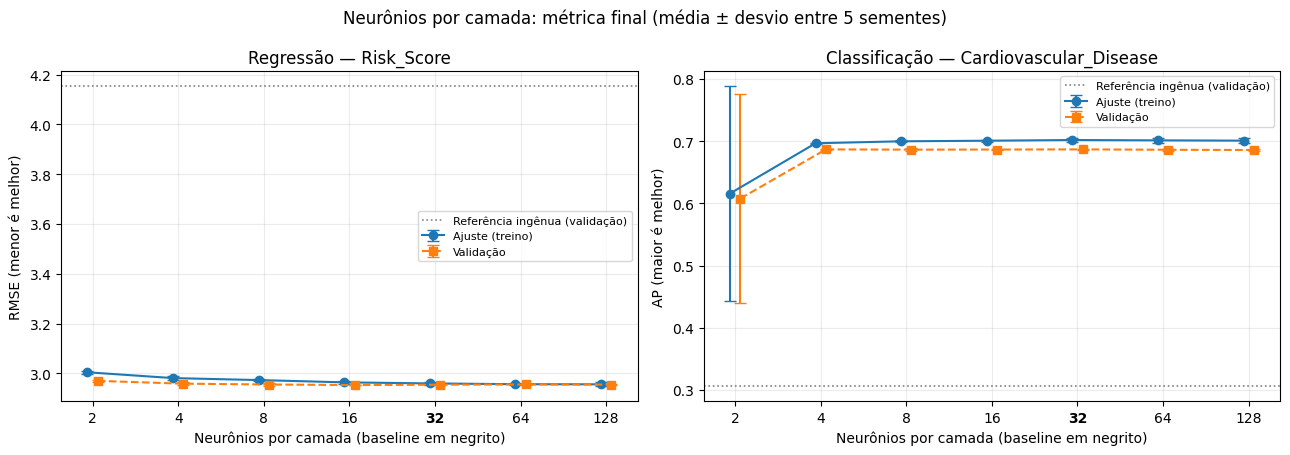

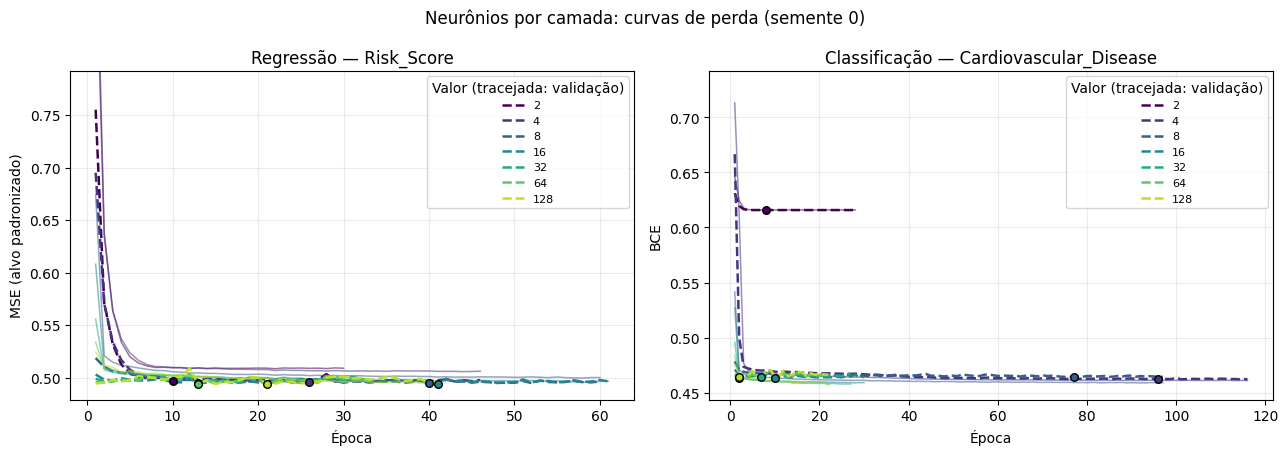

In [14]:
RESULTADOS_ISOLADOS["neuronios"] = executar_estudo("neuronios")

**Análise — neurônios por camada.**

**Evidência.** Na regressão, a rede com 2 neurônios tem o maior erro tanto no ajuste quanto na validação (RMSE de validação próximo de 2,97, contra cerca de 2,955 na referência); com 4 neurônios o erro já cai, e de 8 a 128 neurônios o RMSE de validação permanece entre aproximadamente 2,953 e 2,956, dentro da variação entre sementes. Na classificação, com 2 neurônios a AP média cai para cerca de 0,61, com desvio muito alto: em uma das sementes a rede praticamente não aprendeu, enquanto nas demais o desempenho é próximo ao das redes maiores; de 4 a 128 neurônios, a AP de validação fica entre cerca de 0,686 e 0,687. Ao mesmo tempo, o número de parâmetros passa de 23 para mais de 17 mil.

**Mecanismo.** Com 2 neurônios, a capacidade é insuficiente para representar a relação entre as features e o alvo (**viés alto, subajuste**), e a rede fica sujeita a inicializações desfavoráveis: com apenas dois neurônios ReLU, se eles deixam de ser ativados, a saída perde quase toda a informação, o que é compatível com a semente que falhou na classificação. A partir de cerca de 8 a 16 neurônios, a capacidade deixa de ser o fator limitante. O aumento adicional de neurônios passa a ser usado para ajustar melhor o subconjunto de ajuste, e não a validação: na regressão, o RMSE de ajuste diminui enquanto o de validação permanece estável (o gap, que é positivo porque a validação tem erro menor que o ajuste neste problema, encolhe); na classificação, a AP de ajuste sobe levemente, o gap aumenta e a época do melhor estado cai de cerca de 70 (4 neurônios) para cerca de 6 (128 neurônios). Esses sinais são compatíveis com um aumento de **variância**, contido pelo *early stopping*, que interrompe o treinamento antes que ele prejudique a validação.

**Conclusão prática.** Para estes dados, 16 a 32 neurônios por camada são suficientes; redes maiores multiplicam o número de parâmetros sem ganho de validação, e redes com 2 neurônios são insuficientes e instáveis.

## 3.2 Número de camadas ocultas

**Hipótese.** Camadas adicionais compõem transformações não lineares e aumentam a capacidade, mas também o número de parâmetros (cada camada intermediária de 32 neurônios acrescenta $32^2 + 32 = 1.056$) e a dificuldade de otimização, porque o gradiente percorre mais multiplicações até as primeiras camadas. Para dados tabulares, 1 a 2 camadas costumam ser suficientes. Espera-se desempenho de validação semelhante entre 1 e 2 camadas e nenhum ganho com 3 ou 5, possivelmente com convergência mais irregular, maior variância entre sementes e maior tempo por época.


CAMADAS OCULTAS — Regressão — Risk_Score


Valor,Parâmetros,RMSE ajuste — média,RMSE ajuste — desvio,RMSE validação — média,RMSE validação — desvio,Gap — média,Gap — desvio,R² validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
1,257,2.9674,0.0062,2.9537,0.0019,0.0136,0.0075,0.4946,33.2000,53.2000,26.6768,10.0853,0,5
2,1313,2.9599,0.0057,2.9548,0.0028,0.0051,0.0060,0.4942,21.2000,41.2000,24.4654,6.8176,0,5
3,2369,2.9591,0.0040,2.9550,0.0033,0.0041,0.0044,0.4941,25.8000,45.8000,30.9082,8.2232,0,5
5,4481,2.9585,0.0050,2.9556,0.0019,0.0028,0.0036,0.4939,25.0000,45.0000,39.3565,10.3626,0,5



CAMADAS OCULTAS — Classificação — Cardiovascular_Disease


Valor,Parâmetros,AP ajuste — média,AP ajuste — desvio,AP validação — média,AP validação — desvio,Gap — média,Gap — desvio,ROC-AUC validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
1,257,0.7010,0.0019,0.6874,0.0009,0.0136,0.0027,0.8179,28.4000,48.4000,24.3143,9.2010,0,5
2,1313,0.7020,0.0030,0.6869,0.0013,0.0151,0.0041,0.8179,13.4000,33.4000,20.2416,3.8574,0,5
3,2369,0.7026,0.0030,0.6848,0.0023,0.0178,0.0033,0.8165,10.2000,30.2000,20.5589,3.8771,0,5
5,4481,0.7015,0.0028,0.6857,0.0014,0.0158,0.0025,0.8170,8.2000,28.2000,24.7295,4.8895,0,5


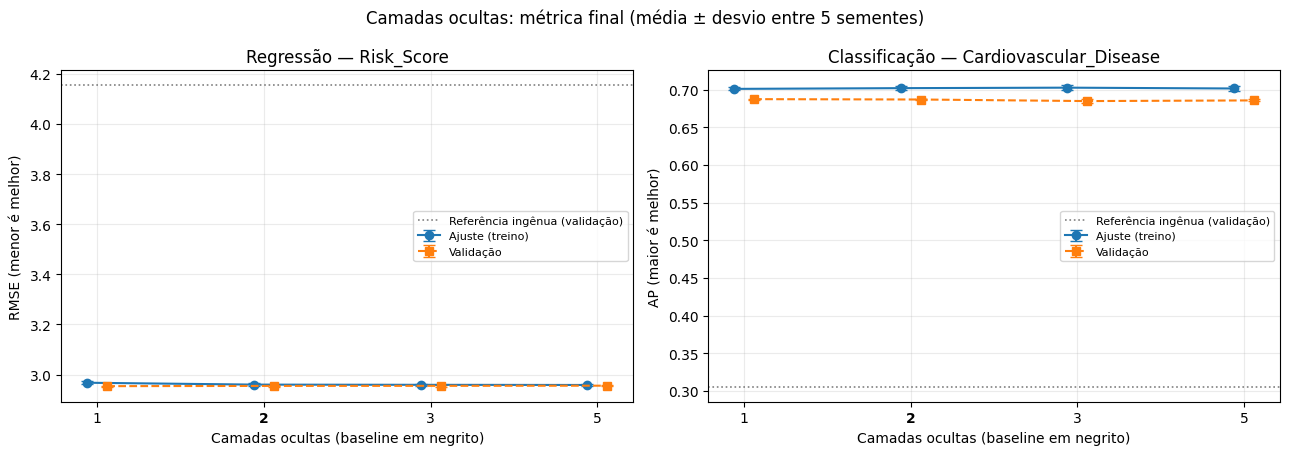

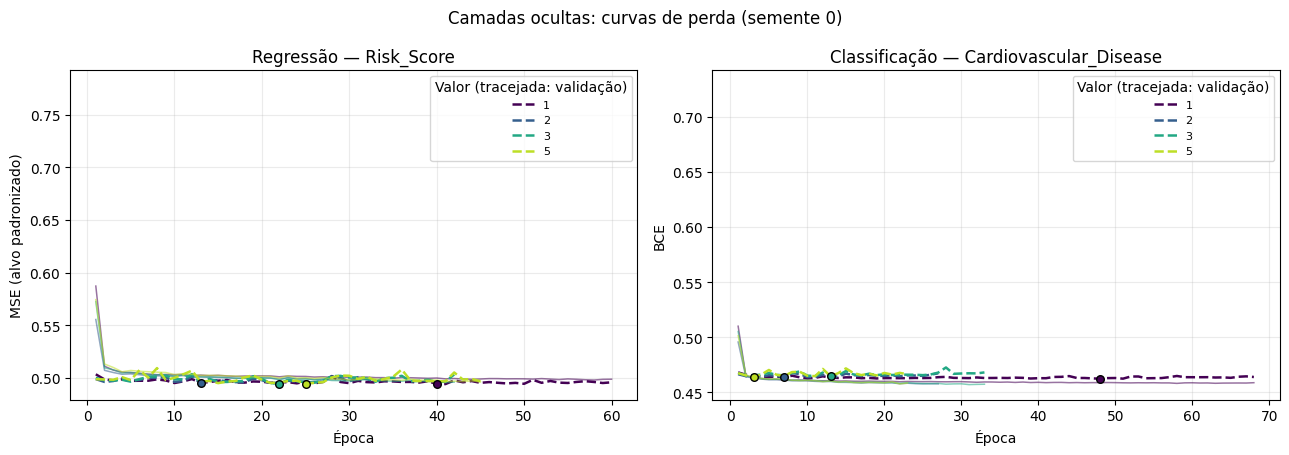

In [15]:
RESULTADOS_ISOLADOS["camadas"] = executar_estudo("camadas")

**Análise — número de camadas ocultas.**

**Evidência.** Na regressão, o RMSE de validação varia menos que a variação entre sementes entre 1 e 5 camadas (todos próximos de 2,954 a 2,956); a rede com 1 camada tem o menor valor médio, com cerca de 257 parâmetros, contra 1.313 da referência e 4.481 com 5 camadas. Na classificação, a rede com 1 camada também tem a maior AP média (cerca de 0,687), e 3 e 5 camadas ficam ligeiramente abaixo (cerca de 0,685 a 0,686), diferença classificada como inconclusiva. O tempo por época cresce com a profundidade (de cerca de 0,5 s com 1 camada para cerca de 0,9 s com 5, na regressão), e, na classificação, redes mais profundas atingem o melhor estado mais cedo e apresentam gap um pouco maior.

**Mecanismo.** Camadas adicionais aumentam a capacidade por composição de transformações, o que só traz ganho quando a relação a ser aprendida exige essa composição. Com seis features, quatro delas binárias, uma única camada oculta já representa as interações relevantes. A profundidade extra acrescenta parâmetros e custo por época e, na classificação, acelera o ajuste ao subconjunto de treino (melhor estado mais cedo, gap maior), sinal compatível com mais variância sem contrapartida na validação.

**Conclusão prática.** Uma ou duas camadas ocultas são suficientes; a profundidade adicional aumenta custo e parâmetros sem melhora mensurável. Pela parcimônia, uma camada é uma candidata natural na busca final.

## 3.3 Função de ativação

**Hipótese.** A ativação introduz a não linearidade; sem ela, a rede seria equivalente a um modelo linear. A ReLU é barata e não satura para entradas positivas. A LeakyReLU mantém um gradiente pequeno para entradas negativas, evitando neurônios "mortos". A Tanh é centrada em zero, mas satura nos extremos. A Sigmoid satura e tem derivada máxima de 0,25, o que reduz o gradiente a cada camada (**gradientes que desaparecem**) e tende a tornar a convergência mais lenta. A GELU é suave e mais cara de calcular. Como a rede é rasa (2 camadas), espera-se desempenho final semelhante entre as ativações, com diferenças principalmente na velocidade de convergência: a Sigmoid deve precisar de mais épocas.


FUNÇÃO DE ATIVAÇÃO — Regressão — Risk_Score


Valor,Parâmetros,RMSE ajuste — média,RMSE ajuste — desvio,RMSE validação — média,RMSE validação — desvio,Gap — média,Gap — desvio,R² validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
ReLU,1313,2.9599,0.0057,2.9548,0.0028,0.0051,0.0060,0.4942,21.2000,41.2000,24.4654,6.8176,0,5
LeakyReLU,1313,2.9616,0.0036,2.9531,0.0021,0.0084,0.0037,0.4948,22.2000,42.2000,24.7086,4.4936,0,5
Tanh,1313,2.9674,0.0048,2.9550,0.0029,0.0124,0.0061,0.4941,35.4000,55.4000,32.4666,7.3334,0,5
Sigmoid,1313,2.9729,0.0023,2.9541,0.0008,0.0188,0.0030,0.4944,68.2000,88.2000,52.5753,4.7929,0,5
GELU,1313,2.9663,0.0043,2.9555,0.0010,0.0108,0.0038,0.4939,32.6000,52.6000,35.6007,6.0315,0,5



FUNÇÃO DE ATIVAÇÃO — Classificação — Cardiovascular_Disease


Valor,Parâmetros,AP ajuste — média,AP ajuste — desvio,AP validação — média,AP validação — desvio,Gap — média,Gap — desvio,ROC-AUC validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
ReLU,1313,0.7020,0.0030,0.6869,0.0013,0.0151,0.0041,0.8179,13.4000,33.4000,20.2416,3.8574,0,5
LeakyReLU,1313,0.7019,0.0020,0.6871,0.0014,0.0149,0.0031,0.8176,13.8000,33.8000,20.0789,3.5408,0,5
Tanh,1313,0.7004,0.0027,0.6866,0.0022,0.0138,0.0046,0.8189,23.2000,43.2000,25.6719,8.9058,0,5
Sigmoid,1313,0.6999,0.0007,0.6866,0.0004,0.0133,0.0008,0.8187,76.0000,96.0000,56.8239,7.2823,0,5
GELU,1313,0.7015,0.0011,0.6871,0.0013,0.0144,0.0023,0.8187,22.0000,42.0000,28.7550,2.6257,0,5


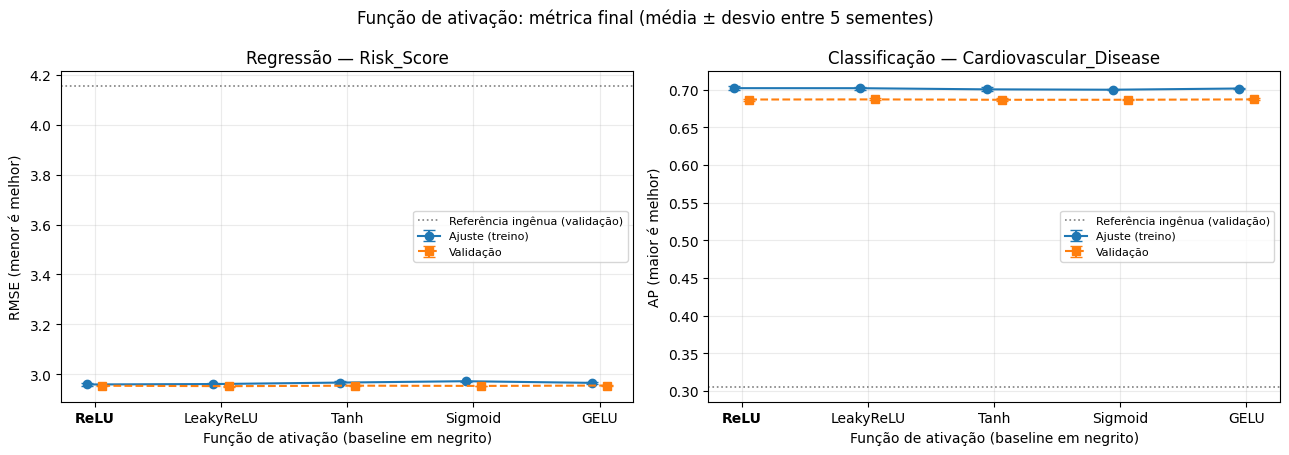

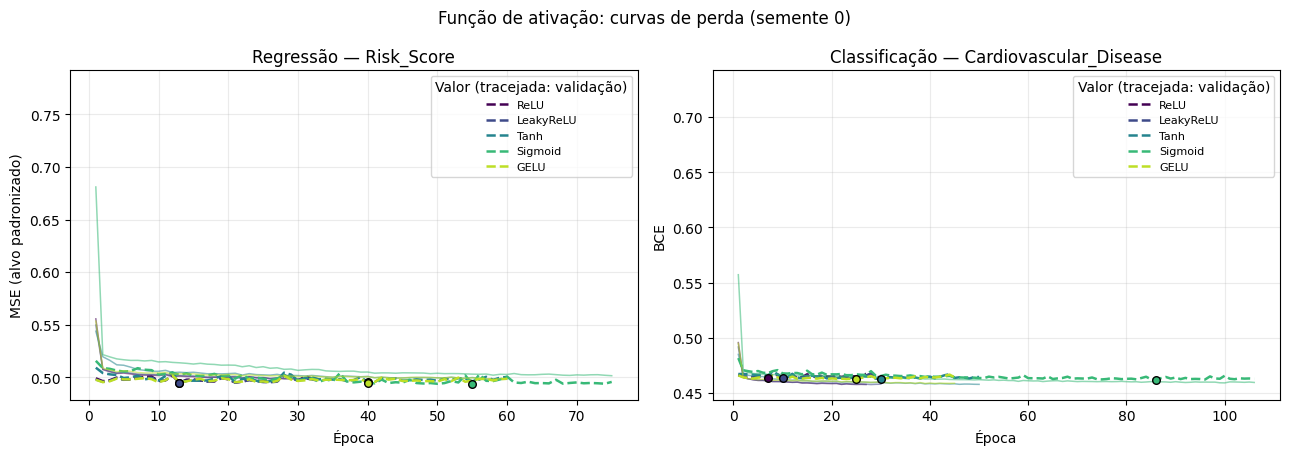

In [16]:
RESULTADOS_ISOLADOS["ativacao"] = executar_estudo("ativacao")

**Análise — função de ativação.**

**Evidência.** O desempenho final é praticamente o mesmo para as cinco ativações nos dois problemas: RMSE de validação entre cerca de 2,953 e 2,956 e AP entre cerca de 0,686 e 0,687, diferenças dentro da variação entre sementes ou inconclusivas. A diferença está na convergência: com a Sigmoid, a época do melhor estado passa de cerca de 21 (ReLU) para cerca de 68 na regressão e de cerca de 13 para cerca de 76 na classificação, e o tempo de treinamento mais que dobra. Tanh e GELU ficam em posição intermediária.

**Mecanismo.** A derivada da Sigmoid é no máximo 0,25 e se aproxima de zero quando a entrada é grande em módulo (saturação); a cada camada, o gradiente é multiplicado por esses valores pequenos, e as atualizações dos pesos ficam menores, o que torna o treinamento mais lento. A hipótese de gradientes que desaparecem se confirma na **velocidade** de convergência; como a rede tem apenas duas camadas e o *early stopping* permite treinar até a estabilização, o efeito não chega a comprometer o desempenho final. A ReLU e a LeakyReLU não saturam para entradas positivas e convergem mais rapidamente.

**Conclusão prática.** A ReLU (ou a LeakyReLU) oferece o mesmo desempenho com o menor custo de treinamento; não há motivo, nestes dados, para trocar a ativação da referência.

## 3.4 Otimizador

**Hipótese.** O SGD atualiza os pesos na direção do gradiente com passo fixo; com taxa de $10^{-3}$, o passo é pequeno e a convergência tende a ser lenta, podendo não se completar em 200 épocas. O momentum acumula a direção dos gradientes anteriores e acelera a descida. RMSprop, Adam e AdamW adaptam o passo de cada parâmetro à magnitude recente dos gradientes, o que tende a acelerar a convergência com essa taxa. O custo de memória também difere: o SGD não guarda estado; momentum e RMSprop guardam um vetor por parâmetro; Adam e AdamW guardam dois. **Esta comparação vale para a taxa fixada em $10^{-3}$**: cada otimizador tem sua faixa adequada de taxa de aprendizado, e o resultado não é uma comparação geral entre eles.


OTIMIZADOR — Regressão — Risk_Score


Valor,Parâmetros,RMSE ajuste — média,RMSE ajuste — desvio,RMSE validação — média,RMSE validação — desvio,Gap — média,Gap — desvio,R² validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
SGD,1313,2.9756,0.0025,2.9571,0.0023,0.0185,0.0021,0.4934,134.0000,151.0000,66.8786,16.0709,0,5
SGD+momentum,1313,2.9654,0.0071,2.9538,0.0018,0.0116,0.0066,0.4945,52.4000,72.4000,34.2634,13.3685,0,5
RMSprop,1313,2.9610,0.0018,2.9531,0.0012,0.0079,0.0027,0.4948,20.2000,40.2000,21.4938,2.9707,0,5
Adam,1313,2.9599,0.0057,2.9548,0.0028,0.0051,0.0060,0.4942,21.2000,41.2000,24.4654,6.8176,0,5
AdamW,1313,2.9599,0.0057,2.9548,0.0028,0.0051,0.0060,0.4942,21.2000,41.2000,24.5515,7.0933,0,5



OTIMIZADOR — Classificação — Cardiovascular_Disease


Valor,Parâmetros,AP ajuste — média,AP ajuste — desvio,AP validação — média,AP validação — desvio,Gap — média,Gap — desvio,ROC-AUC validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
SGD,1313,0.6979,0.0006,0.6865,0.0015,0.0114,0.0020,0.8164,199.8000,200.0000,88.8873,1.2192,0,5
SGD+momentum,1313,0.7000,0.0005,0.6874,0.0018,0.0125,0.0022,0.8180,54.2000,74.2000,35.3651,5.1542,0,5
RMSprop,1313,0.7012,0.0012,0.6869,0.0007,0.0143,0.0015,0.8176,11.4000,31.4000,17.0044,1.4535,0,5
Adam,1313,0.7020,0.0030,0.6869,0.0013,0.0151,0.0041,0.8179,13.4000,33.4000,20.2416,3.8574,0,5
AdamW,1313,0.7020,0.0030,0.6869,0.0013,0.0151,0.0041,0.8179,13.4000,33.4000,20.1458,3.5975,0,5


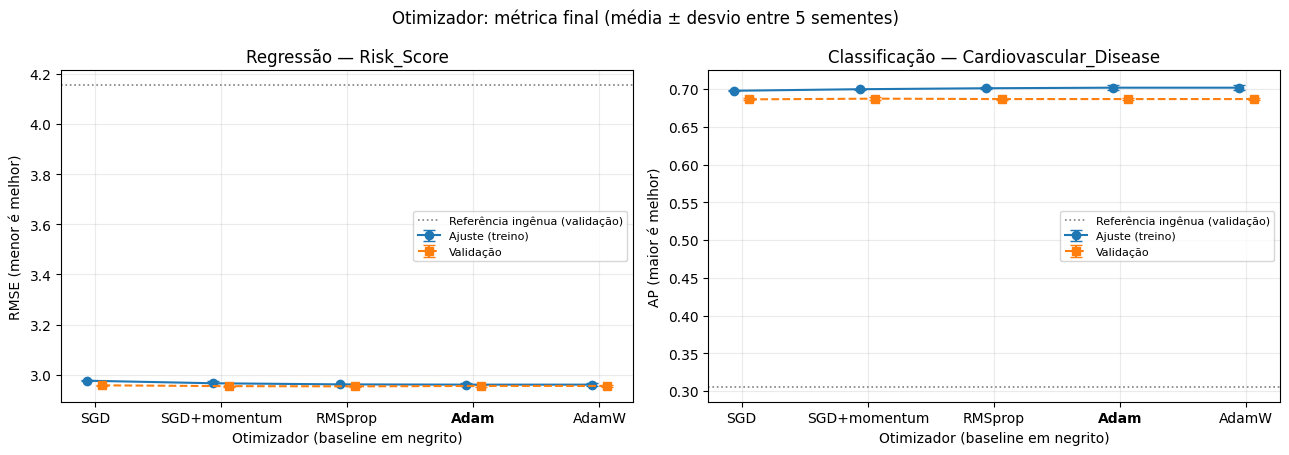

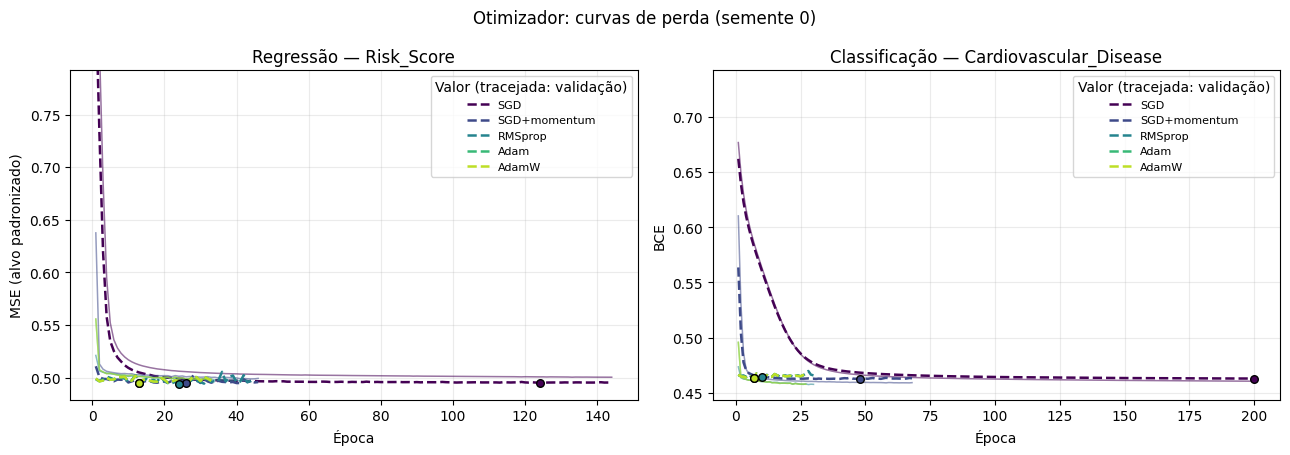

In [17]:
RESULTADOS_ISOLADOS["otimizador"] = executar_estudo("otimizador")

**Análise — otimizador (taxa de aprendizado fixada em $10^{-3}$).**

**Evidência.** Com a taxa da referência, todos os otimizadores alcançam desempenho de validação semelhante (RMSE entre cerca de 2,953 e 2,957; AP entre cerca de 0,686 e 0,687). A diferença está no custo: o SGD precisa de cerca de 150 épocas na regressão e atinge o limite de 200 épocas na classificação, levando de três a quatro vezes mais tempo que os otimizadores adaptativos; o SGD com momentum fica em posição intermediária; RMSprop, Adam e AdamW convergem em cerca de 30 a 40 épocas. Adam e AdamW produzem resultados idênticos.

**Mecanismo.** Com passo fixo e pequeno, o SGD avança devagar em direção ao mínimo; o momentum acumula a direção dos gradientes anteriores e acelera a descida; RMSprop e Adam ajustam o passo de cada parâmetro pela magnitude recente dos gradientes, o que torna $10^{-3}$ um passo efetivo adequado. A igualdade entre Adam e AdamW é esperada: os dois diferem apenas na forma de aplicar o *weight decay* (acoplado ao gradiente no Adam, desacoplado no AdamW), e no estudo isolado o *weight decay* é zero — o resultado confirma a consistência da implementação. Na classificação, a AP do SGD já está no patamar dos demais mesmo sem a perda ter estabilizado, o que indica que a ordenação dos registros se estabiliza antes da perda.

**Conclusão prática.** Na taxa de $10^{-3}$, os otimizadores adaptativos alcançam o mesmo desempenho com muito menos tempo. A conclusão vale para essa taxa: o SGD normalmente exige taxas maiores, e a comparação entre Adam e AdamW só é informativa com *weight decay* positivo; por isso, otimizador, taxa de aprendizado e *weight decay* variam em conjunto na busca aleatória.

## 3.5 Taxa de aprendizado

**Hipótese.** A atualização $\theta \leftarrow \theta - \eta \nabla_\theta L$ define o tamanho do passo. Com $\eta$ muito baixo ($10^{-4}$), a perda cai lentamente e o treinamento pode exigir muitas épocas. Com $\eta$ adequado ($10^{-3}$), a convergência é estável. Com $\eta$ alto ($10^{-2}$ a $10^{-1}$), os passos podem ultrapassar o mínimo, gerando oscilação na perda de validação e desempenho pior. Com $\eta = 1$, espera-se instabilidade: divergência numérica ou um estado degenerado, em que a rede deixa de aprender (por exemplo, neurônios ReLU que passam a ter saída sempre zero).


TAXA DE APRENDIZADO — Regressão — Risk_Score


Valor,Parâmetros,RMSE ajuste — média,RMSE ajuste — desvio,RMSE validação — média,RMSE validação — desvio,Gap — média,Gap — desvio,R² validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
0.0001,1313,2.9654,0.0042,2.9548,0.0020,0.0106,0.0029,0.4942,75.0000,95.0000,56.3990,19.2883,0,5
0.001,1313,2.9599,0.0057,2.9548,0.0028,0.0051,0.0060,0.4942,21.2000,41.2000,24.4654,6.8176,0,5
0.01,1313,2.9727,0.0029,2.9563,0.0022,0.0164,0.0013,0.4937,17.4000,37.4000,22.4583,3.2307,0,5
0.1,1313,3.0234,0.0100,2.9884,0.0057,0.0350,0.0084,0.4826,7.8000,27.8000,16.4028,2.9570,0,5
1,1313,3.8554,0.4546,3.8095,0.4475,0.0459,0.0095,0.1500,8.2000,28.2000,18.5535,5.5136,0,5



TAXA DE APRENDIZADO — Classificação — Cardiovascular_Disease


Valor,Parâmetros,AP ajuste — média,AP ajuste — desvio,AP validação — média,AP validação — desvio,Gap — média,Gap — desvio,ROC-AUC validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
0.0001,1313,0.7005,0.0017,0.6870,0.0015,0.0135,0.0031,0.8173,56.0000,76.0000,47.5122,16.8630,0,5
0.001,1313,0.7020,0.0030,0.6869,0.0013,0.0151,0.0041,0.8179,13.4000,33.4000,20.2416,3.8574,0,5
0.01,1313,0.7014,0.0042,0.6837,0.0053,0.0177,0.0022,0.8179,23.6000,43.6000,26.3733,5.2595,0,5
0.1,1313,0.6237,0.0558,0.6182,0.0542,0.0055,0.0031,0.7996,7.0000,27.0000,16.1885,1.9121,0,5
1,1313,0.3060,0.0000,0.3059,0.0000,0.0001,0.0000,0.5000,8.4000,28.4000,17.6415,6.1943,0,5


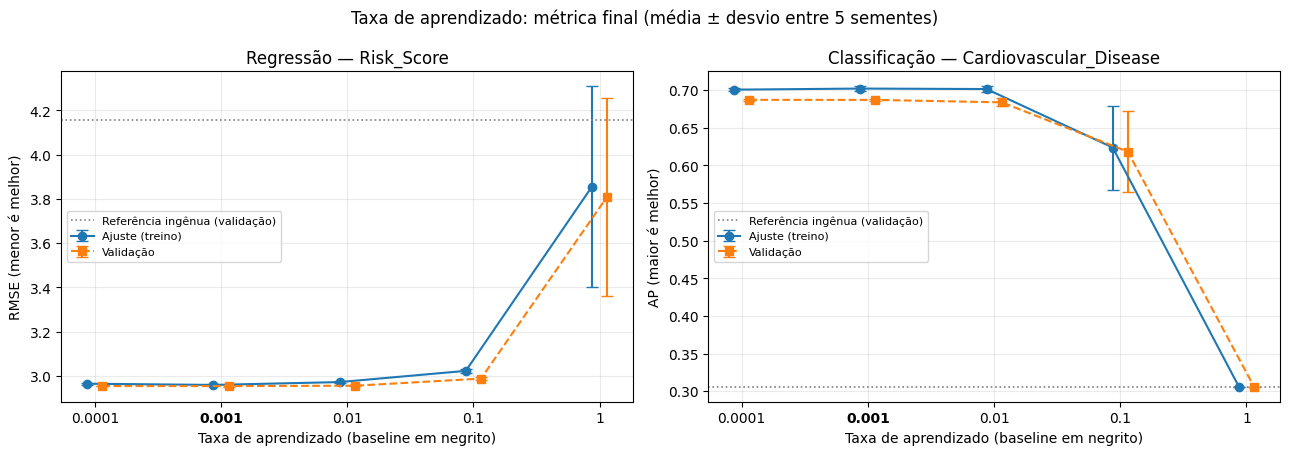

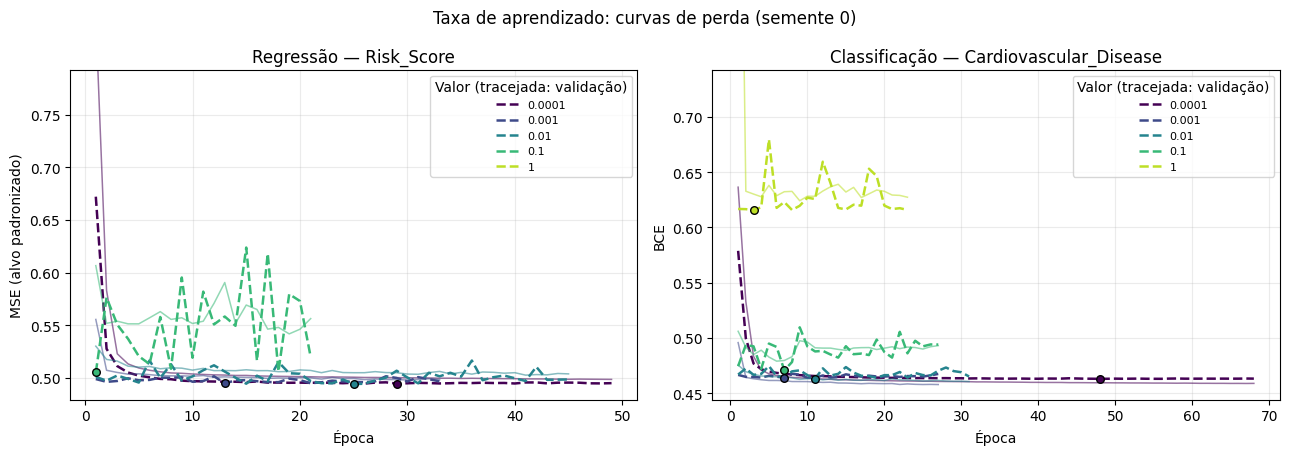

In [18]:
RESULTADOS_ISOLADOS["lr"] = executar_estudo("lr")

**Análise — taxa de aprendizado.**

**Evidência.** Este é o hiperparâmetro de maior impacto nos dois problemas. Com $10^{-4}$ e $10^{-3}$, o desempenho é o mesmo (RMSE próximo de 2,955; AP próxima de 0,687), mas $10^{-4}$ precisa de cerca de duas a três vezes mais épocas. Com $10^{-2}$, o desempenho cai pouco, mas a classificação já mostra maior variação entre sementes. Com $10^{-1}$, a degradação é clara (RMSE próximo de 2,99; AP próxima de 0,62, com grande variação), e o melhor estado ocorre logo nas primeiras épocas. Com taxa igual a 1, a regressão tem RMSE médio próximo de 3,8, com grande variação entre sementes, e a classificação produz, em todas as sementes, AP igual à prevalência e ROC-AUC igual a 0,5 — a rede passa a atribuir a mesma saída a todos os registros. Nenhuma execução teve perda não finita: a falha ocorre sem divergência numérica.

**Mecanismo.** A taxa controla o tamanho do passo $\eta \nabla_\theta L$. Passos pequenos aproximam-se do mínimo de forma estável, porém lenta. Passos grandes ultrapassam o mínimo e fazem a perda oscilar; o melhor estado aparece cedo e não é superado depois. Com $\eta = 1$, as primeiras atualizações são tão grandes que levam a rede a um estado degenerado; uma explicação compatível com a saída constante é que as pré-ativações se tornam negativas para todos os registros, os neurônios ReLU deixam de ser ativados e o gradiente que chega às camadas ocultas se anula, de modo que a rede não consegue se recuperar.

**Conclusão prática.** Com Adam, a faixa segura vai de $10^{-4}$ a $10^{-3}$; $10^{-3}$ oferece o mesmo desempenho com menos épocas. Taxas a partir de $10^{-2}$ trazem instabilidade crescente, e taxas iguais ou maiores que $10^{-1}$ devem ser evitadas com este otimizador.

## 3.6 Tamanho do batch

**Hipótese.** O gradiente de cada lote é uma estimativa do gradiente do conjunto completo; lotes pequenos produzem estimativas mais **ruidosas**, e lotes grandes, mais estáveis. Lotes pequenos também fazem mais atualizações por época (1.600 com *batch* 8), mas cada época custa mais tempo, porque há mais passos de otimização. Com o mesmo número máximo de épocas, lotes muito grandes fazem poucas atualizações: no extremo de 12.800 (o ajuste inteiro), são apenas 200 passos em todo o treinamento, o que deve levar a **subajuste por falta de atualizações**, e não apenas pela redução do ruído. Espera-se tempo por época decrescente com o *batch*, desempenho semelhante entre 8 e 512 e pior com o lote completo.


TAMANHO DO BATCH — Regressão — Risk_Score


Valor,Parâmetros,RMSE ajuste — média,RMSE ajuste — desvio,RMSE validação — média,RMSE validação — desvio,Gap — média,Gap — desvio,R² validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
8,1313,2.9630,0.0074,2.9549,0.0016,0.0080,0.0063,0.4942,16.4000,36.4000,72.3344,10.3870,0,5
32,1313,2.9599,0.0057,2.9548,0.0028,0.0051,0.0060,0.4942,21.2000,41.2000,24.4654,6.8176,0,5
128,1313,2.9600,0.0026,2.9540,0.0024,0.0060,0.0038,0.4945,33.8000,53.8000,12.9808,2.7745,0,5
512,1313,2.9647,0.0011,2.9555,0.0025,0.0092,0.0034,0.4939,38.6000,58.6000,9.2422,1.4514,0,5
12.800,1313,2.9782,0.0033,2.9606,0.0034,0.0176,0.0023,0.4922,200.0000,200.0000,34.5415,1.6685,0,5



TAMANHO DO BATCH — Classificação — Cardiovascular_Disease


Valor,Parâmetros,AP ajuste — média,AP ajuste — desvio,AP validação — média,AP validação — desvio,Gap — média,Gap — desvio,ROC-AUC validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
8,1313,0.7028,0.0013,0.6851,0.0015,0.0177,0.0021,0.8167,11.0000,31.0000,62.1720,7.0064,0,5
32,1313,0.7020,0.0030,0.6869,0.0013,0.0151,0.0041,0.8179,13.4000,33.4000,20.2416,3.8574,0,5
128,1313,0.7007,0.0013,0.6867,0.0010,0.0139,0.0013,0.8173,15.2000,35.2000,8.2658,2.1475,0,5
512,1313,0.7011,0.0013,0.6865,0.0015,0.0147,0.0024,0.8170,33.2000,53.2000,8.0584,2.6735,0,5
12.800,1313,0.6987,0.0006,0.6854,0.0022,0.0133,0.0021,0.8157,200.0000,200.0000,34.6951,1.6908,0,5


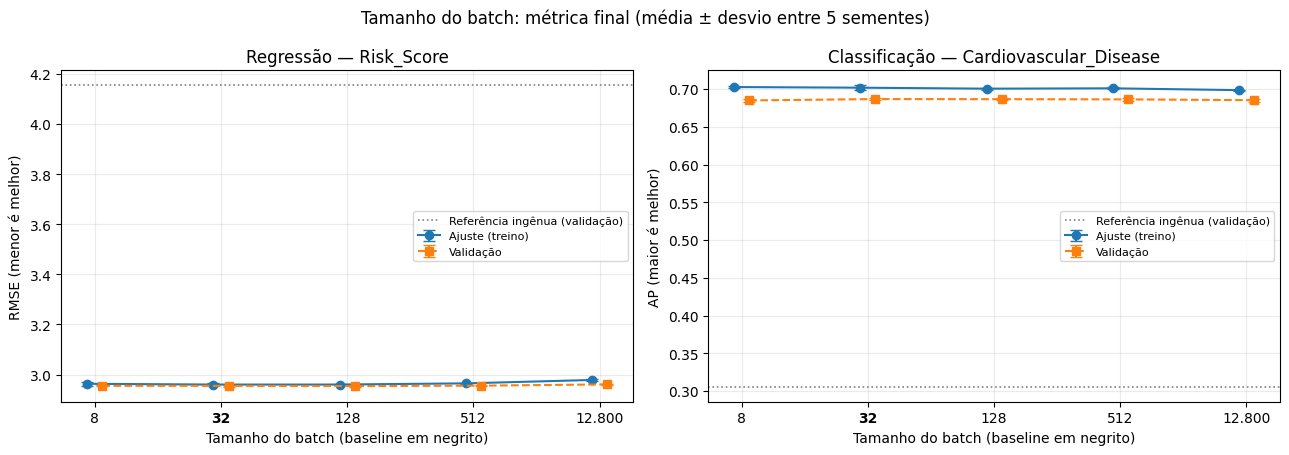

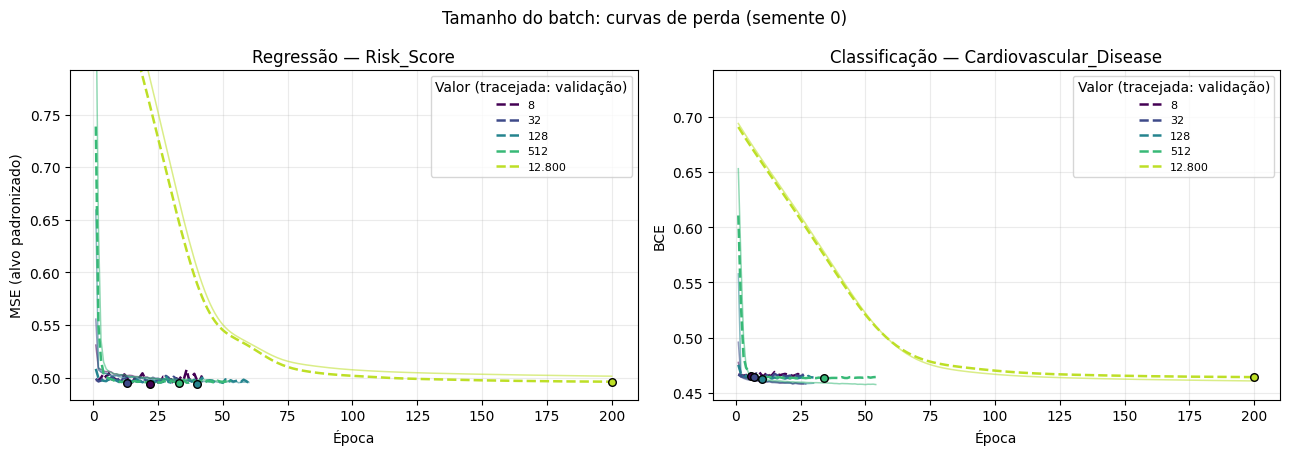

In [19]:
RESULTADOS_ISOLADOS["batch"] = executar_estudo("batch")

**Análise — tamanho do batch.**

**Evidência.** Entre 8 e 512, o desempenho de validação é praticamente o mesmo nos dois problemas, mas o custo muda muito: o tempo por época cai de cerca de 2 s (*batch* 8) para cerca de 0,6 s (32), 0,24 s (128) e 0,16 s (512), e o tempo total de treinamento com 128 é cerca de metade do da referência. Com o lote completo (12.800), o treinamento chega a 200 épocas ainda melhorando (melhor estado na última época) e termina com desempenho um pouco pior, inclusive no ajuste. Na classificação, o *batch* 8 é ligeiramente pior que o 32 em todas as sementes, embora a diferença média seja pequena.

**Mecanismo.** O número de atualizações por época é o tamanho do ajuste dividido pelo *batch*: 1.600 com 8, 400 com 32, 100 com 128, 25 com 512 e apenas 1 com o lote completo. Lotes pequenos geram muitas atualizações com gradientes ruidosos e cada época custa mais, porque há mais passos; lotes grandes geram gradientes estáveis, mas poucas atualizações, de modo que precisam de mais épocas para convergir (a época do melhor estado cresce com o *batch*). No lote completo, as 200 épocas correspondem a só 200 atualizações em todo o treinamento, insuficientes para convergir: a piora decorre principalmente da **falta de atualizações** (subajuste), e não da ausência de ruído no gradiente.

**Conclusão prática.** *Batches* de 128 a 512 alcançam o mesmo desempenho da referência com uma fração do tempo de treinamento; o *batch* 8 é o mais caro sem vantagem, e o lote completo exigiria muito mais épocas para convergir.

## 3.7 Weight decay (regularização L2)

**Hipótese.** O *weight decay* equivale a acrescentar à perda uma penalidade proporcional ao quadrado dos pesos (no PyTorch, o termo $\lambda\,\theta$ é somado ao gradiente), favorecendo pesos menores e funções mais suaves; o efeito esperado é **reduzir a variância**, à custa de algum aumento de viés. Como o baseline não mostrou evidência consistente de sobreajuste, espera-se pouco ou nenhum ganho de validação: valores pequenos ($10^{-5}$ e $10^{-4}$) devem ser praticamente neutros, e o maior valor ($10^{-2}$) pode restringir demais a rede, piorando ajuste e validação (subajuste).


WEIGHT DECAY (L2) — Regressão — Risk_Score


Valor,Parâmetros,RMSE ajuste — média,RMSE ajuste — desvio,RMSE validação — média,RMSE validação — desvio,Gap — média,Gap — desvio,R² validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
0,1313,2.9599,0.0057,2.9548,0.0028,0.0051,0.0060,0.4942,21.2000,41.2000,24.4654,6.8176,0,5
1e-05,1313,2.9615,0.0038,2.9547,0.0021,0.0067,0.0045,0.4942,19.6000,39.6000,23.9794,5.1772,0,5
0.0001,1313,2.9610,0.0057,2.9543,0.0020,0.0068,0.0057,0.4944,21.2000,41.2000,25.3412,7.5287,0,5
0.001,1313,2.9630,0.0019,2.9518,0.0027,0.0112,0.0027,0.4952,45.6000,65.6000,41.2491,12.0405,0,5
0.01,1313,2.9828,0.0020,2.9608,0.0015,0.0220,0.0024,0.4921,30.8000,50.8000,31.6247,14.4734,0,5



WEIGHT DECAY (L2) — Classificação — Cardiovascular_Disease


Valor,Parâmetros,AP ajuste — média,AP ajuste — desvio,AP validação — média,AP validação — desvio,Gap — média,Gap — desvio,ROC-AUC validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
0,1313,0.7020,0.0030,0.6869,0.0013,0.0151,0.0041,0.8179,13.4000,33.4000,20.2416,3.8574,0,5
1e-05,1313,0.7019,0.0024,0.6869,0.0013,0.0151,0.0034,0.8179,14.0000,34.0000,20.7759,3.7511,0,5
0.0001,1313,0.7027,0.0024,0.6867,0.0012,0.0160,0.0035,0.8178,16.2000,36.2000,22.2505,4.6618,0,5
0.001,1313,0.7008,0.0009,0.6882,0.0013,0.0126,0.0021,0.8179,29.0000,49.0000,30.9181,8.8608,0,5
0.01,1313,0.6959,0.0005,0.6866,0.0005,0.0093,0.0008,0.8152,33.2000,53.2000,34.0308,8.0555,0,5


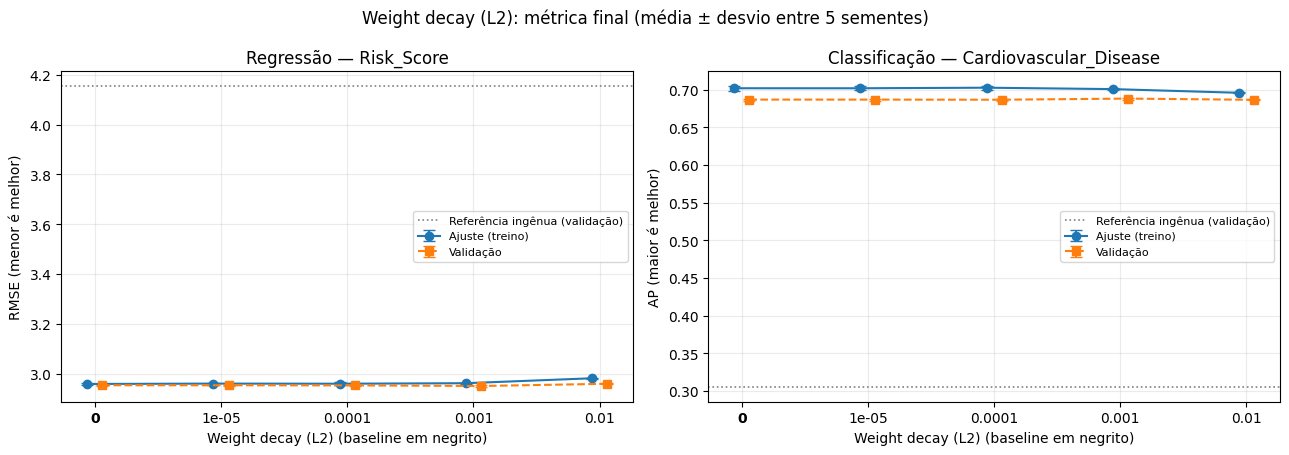

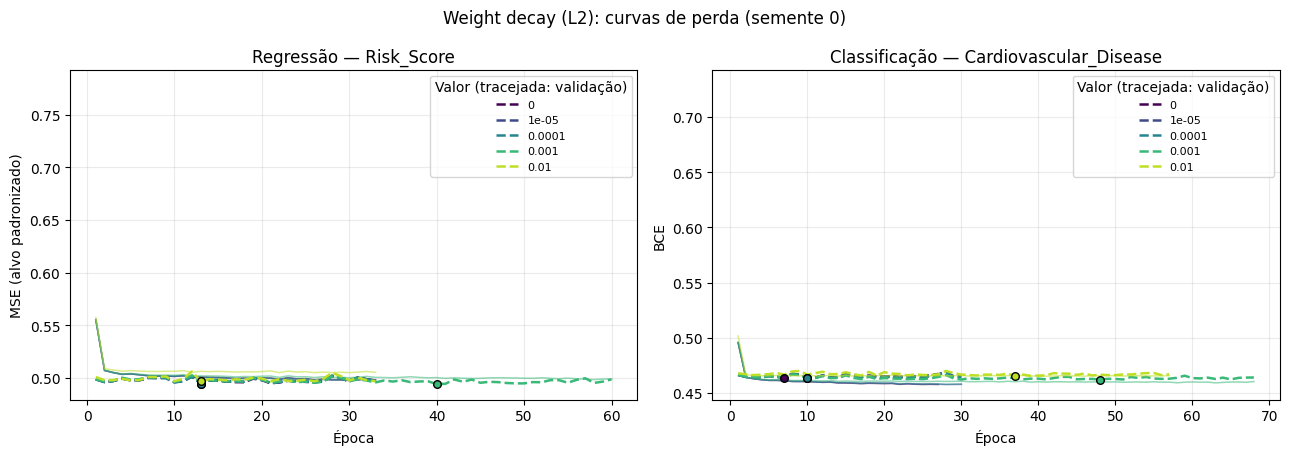

In [20]:
RESULTADOS_ISOLADOS["weight_decay"] = executar_estudo("weight_decay")

**Análise — *weight decay* (regularização L2).**

**Evidência.** Os valores $10^{-5}$ e $10^{-4}$ praticamente não alteram o resultado. Com $10^{-3}$, os dois problemas têm o melhor valor médio de validação do estudo (RMSE próximo de 2,952; AP próxima de 0,688), e, na classificação, o gap de AP diminui em relação à referência; a melhora, porém, é da ordem da variação entre sementes. Com $10^{-2}$, o desempenho piora no ajuste e na validação da regressão, e a classificação apresenta a menor AP de ajuste e a menor ROC-AUC de validação do estudo.

**Mecanismo.** A penalidade L2 reduz a magnitude dos pesos e, com isso, a complexidade efetiva da rede, trocando variância por viés. Valores muito pequenos têm efeito desprezível. Em $10^{-3}$, a redução do gap na classificação é compatível com uma pequena diminuição de variância; em $10^{-2}$, a restrição passa a limitar a capacidade de ajuste (subajuste), o que aparece no aumento do erro de ajuste.

**Conclusão prática.** O *weight decay* não muda substancialmente o desempenho; a faixa entre $10^{-4}$ e $10^{-3}$ é a mais promissora e entra na busca aleatória, onde também permite comparar Adam e AdamW. Valores da ordem de $10^{-2}$ restringem demais esta rede.

## 3.8 Dropout

**Hipótese.** O *dropout* zera aleatoriamente uma fração $p$ das ativações a cada passo de treinamento, impedindo que a rede dependa de neurônios específicos; funciona como regularização estocástica e reduz a variância. Na inferência, com `model.eval()`, todos os neurônios são usados. Como o baseline não mostrou evidência consistente de sobreajuste e a rede é pequena (32 neurônios por camada), espera-se pouco ganho de validação, e valores altos ($p = 0,5$) podem remover capacidade demais, causando subajuste e convergência mais lenta.


DROPOUT — Regressão — Risk_Score


Valor,Parâmetros,RMSE ajuste — média,RMSE ajuste — desvio,RMSE validação — média,RMSE validação — desvio,Gap — média,Gap — desvio,R² validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
0.0,1313,2.9599,0.0057,2.9548,0.0028,0.0051,0.0060,0.4942,21.2000,41.2000,24.4654,6.8176,0,5
0.1,1313,2.9687,0.0042,2.9533,0.0016,0.0154,0.0042,0.4947,23.6000,43.6000,28.1615,8.4107,0,5
0.3,1313,2.9828,0.0058,2.9610,0.0037,0.0218,0.0024,0.4921,18.4000,38.4000,24.7161,7.2372,0,5
0.5,1313,2.9912,0.0067,2.9673,0.0054,0.0239,0.0020,0.4899,37.4000,57.4000,37.4414,11.2710,0,5



DROPOUT — Classificação — Cardiovascular_Disease


Valor,Parâmetros,AP ajuste — média,AP ajuste — desvio,AP validação — média,AP validação — desvio,Gap — média,Gap — desvio,ROC-AUC validação — média,Época do melhor estado — média,Época de parada — média,Tempo (s) — média,Tempo (s) — desvio,Sementes divergentes,Sementes com métricas
0.0,1313,0.7020,0.0030,0.6869,0.0013,0.0151,0.0041,0.8179,13.4000,33.4000,20.2416,3.8574,0,5
0.1,1313,0.7028,0.0018,0.6865,0.0005,0.0164,0.0022,0.8176,15.8000,35.8000,23.3190,4.7829,0,5
0.3,1313,0.7015,0.0006,0.6869,0.0006,0.0146,0.0008,0.8169,22.4000,42.4000,27.6948,2.4943,0,5
0.5,1313,0.6998,0.0014,0.6859,0.0008,0.0139,0.0014,0.8159,32.4000,52.4000,34.5307,20.3413,0,5


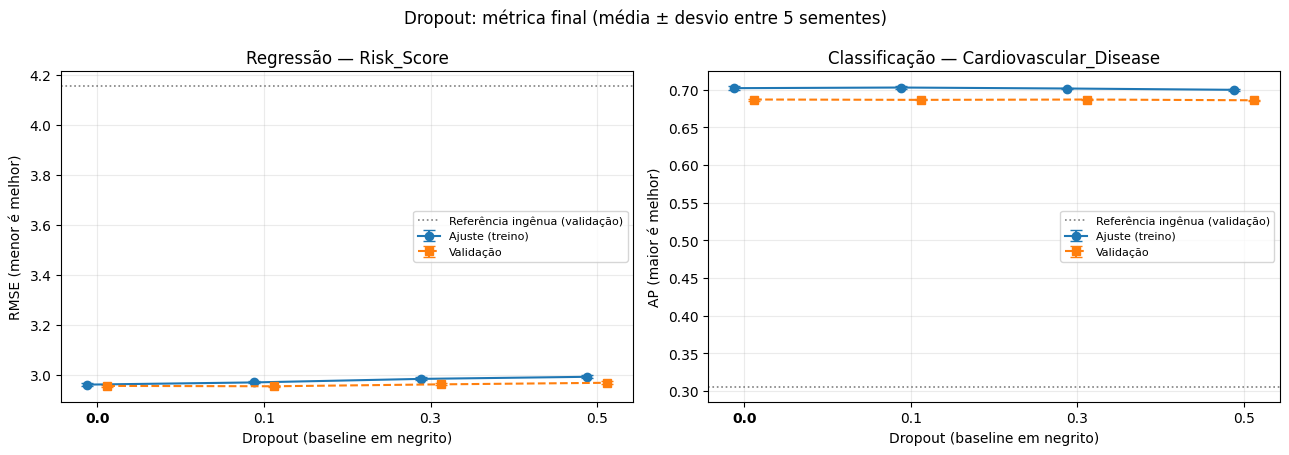

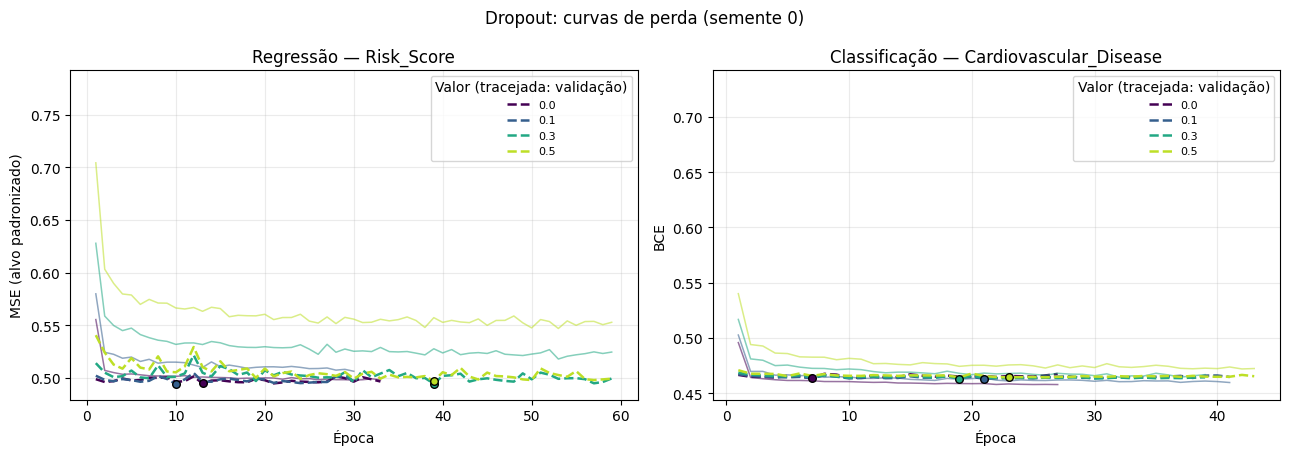

In [21]:
RESULTADOS_ISOLADOS["dropout"] = executar_estudo("dropout")

**Análise — *dropout*.**

**Evidência.** Na regressão, *dropout* de 0,1 é equivalente à referência, e 0,3 e 0,5 pioram o RMSE de validação (até cerca de 2,967 com 0,5) e, principalmente, o de ajuste. Na classificação, a AP de validação muda muito pouco entre os valores testados (diferenças inconclusivas), com leve queda em 0,5.

**Mecanismo.** O *dropout* reduz a variância ao impedir que a rede dependa de neurônios específicos, mas, durante o treinamento, também reduz a capacidade efetiva da rede. Como a referência não mostrou evidência consistente de sobreajuste, não há variância a corrigir, e o efeito que predomina é a perda de capacidade de uma rede pequena (32 neurônios por camada): o erro de ajuste aumenta, sinal de subajuste. A classificação é menos sensível, o que é compatível com a AP depender apenas da ordenação dos registros.

**Conclusão prática.** Nestes dados, o *dropout* não traz benefício; valores acima de 0,1 prejudicam a regressão. Ele pode ser mantido na busca apenas em valores baixos.

## 4. Triagem do espaço da busca aleatória

A triagem definida na Seção 1.1 é aplicada aqui, valor a valor, a partir dos resultados dos estudos isolados. Ela indica regiões que falharam na configuração testada, sem demonstrar que esses valores sejam inúteis em outras combinações. Um valor é **retirado** do espaço da busca aleatória se divergiu na maioria das sementes (pelo menos 3 de 5) ou se não superou a referência ingênua de validação (por mais de 0,001) em nenhuma semente. As divergências isoladas aparecem na tabela, mas não excluem o valor.

In [22]:
TOLERANCIA = 1e-3
log = treino.carregar_log(CAMINHO_LOG)
linhas_exclusao = []
for problema in ("regressao", "classificacao"):
    m, ref = METRICA[problema], REFERENCIA_INGENUA[problema]
    for chave, e in ESTUDOS.items():
        for v in e["valores"]:
            cid = treino.id_configuracao(treino.config_completa(e["config"](v)))
            l = log[(log["problema"] == problema) & (log["config_id"] == cid) & log["semente"].isin(SEMENTES_ESTUDO)]
            val = l[f"{m}_validacao"]
            supera = (val < ref - TOLERANCIA) if not MAIOR_MELHOR[problema] else (val > ref + TOLERANCIA)
            n_div = int(l["divergiu"].sum())
            linhas_exclusao.append({
                "Problema": problema, "Hiperparâmetro": e["nome"], "chave": chave, "Valor": rotulo_valor(chave, v),
                "valor_bruto": v, "Sementes divergentes": int(l["divergiu"].sum()),
                "Sementes que superam a referência": int(supera.sum()),
                "Excluído da busca": n_div >= 3 or int(supera.sum()) == 0,
                "Motivo": "; ".join(m for m, cond in [
                    (f"divergiu em {n_div} de {len(l)} sementes", n_div >= 3),
                    ("não superou a referência ingênua em nenhuma semente", int(supera.sum()) == 0),
                ] if cond) or "—",
            })
tabela_exclusao = pd.DataFrame(linhas_exclusao)
excluidos = tabela_exclusao[tabela_exclusao["Excluído da busca"]]
com_divergencia = tabela_exclusao[(tabela_exclusao["Sementes divergentes"] > 0) & ~tabela_exclusao["Excluído da busca"]]
if len(com_divergencia):
    print("VALORES COM DIVERGÊNCIA ISOLADA (registrados, mas mantidos na busca)")
    display(com_divergencia.drop(columns=["chave", "valor_bruto"]).style.hide(axis="index"))
print("VALORES RETIRADOS DO ESPAÇO DA BUSCA ALEATÓRIA (triagem)")
if len(excluidos):
    display(excluidos.drop(columns=["chave", "valor_bruto"]).style.hide(axis="index"))
else:
    print("Nenhum valor atende aos critérios da triagem.")
tabela_exclusao.drop(columns=["valor_bruto"]).to_csv(
    pasta_tabelas / "hiperparametros_criterio_exclusao.csv", index=False, encoding="utf-8-sig")

VALORES RETIRADOS DO ESPAÇO DA BUSCA ALEATÓRIA (triagem)


Problema,Hiperparâmetro,Valor,Sementes divergentes,Sementes que superam a referência,Excluído da busca,Motivo
classificacao,Taxa de aprendizado,1,0,0,True,não superou a referência ingênua em nenhuma semente


## 5. Tabela de sensibilidade

A tabela ordena os hiperparâmetros pelo impacto observado na métrica de validação, medido como a **amplitude**: a diferença entre a melhor e a pior média de validação entre os valores testados.

**Como ler a amplitude.** Mesmo sem nenhum efeito real, as médias de valores diferentes não seriam idênticas, por causa da variação entre sementes; e a diferença entre a maior e a menor de várias médias tende a ser maior que a diferença entre duas delas. Por isso, a amplitude é comparada com o **desvio típico entre sementes** do estudo (raiz da média das variâncias dos valores testados), em três faixas operacionais:

- **dentro da variação entre sementes:** amplitude até 1 desvio típico — efeito não distinguível neste experimento;
- **inconclusivo:** entre 1 e 2 desvios típicos;
- **acima da variação entre sementes:** mais de 2 desvios típicos.

As faixas são uma convenção de leitura, e não um teste de significância: o desvio entre sementes mede a variação de inicialização, e não a incerteza da amostra de validação. Além disso, comparar a amplitude com desvios calculados separadamente para cada valor não quantifica diretamente a variação da **diferença** entre dois valores. Há ainda um viés de seleção: o melhor e o pior valor são escolhidos com os mesmos resultados usados para medir a diferença entre eles, e, entre vários valores, os extremos tendem a ter sido favorecidos ou prejudicados pelo acaso. A amplitude tende, portanto, a superestimar o efeito, e a tabela é uma descrição, e não uma medida de significância ou da incerteza associada à amostra de validação. A tabela traz também a **diferença pareada por semente** entre o melhor e o pior valor (média, desvio e número de sementes em que o melhor valor de fato superou o pior), que aproveita o fato de todas as configurações usarem as mesmas sementes.

Valores que falham de forma extrema (por exemplo, uma taxa de aprendizado com a qual a rede não aprende) podem dominar a amplitude. Por isso, a tabela mostra também a amplitude calculada **sem os valores excluídos pelo critério da Seção 4**, que descreve a sensibilidade dentro da faixa utilizável.

In [23]:
def faixa(amplitude, desvio_tipico):
    if not np.isfinite(amplitude):
        return "—"
    razao = amplitude / desvio_tipico
    if razao <= 1:
        return "dentro da variação entre sementes"
    return "inconclusivo" if razao <= 2 else "acima da variação entre sementes"

linhas_sens = []
for problema in ("regressao", "classificacao"):
    nm = NOME_METRICA[problema]
    for chave, e in ESTUDOS.items():
        t = RESULTADOS_ISOLADOS[chave][problema]
        medias = t[f"{nm} validação — média"]
        desvios = t[f"{nm} validação — desvio"]
        melhor_idx = medias.idxmin() if not MAIOR_MELHOR[problema] else medias.idxmax()
        pior_idx = medias.idxmax() if not MAIOR_MELHOR[problema] else medias.idxmin()
        excl = tabela_exclusao[(tabela_exclusao["Problema"] == problema) & (tabela_exclusao["chave"] == chave)]
        mantidos = ~excl["Excluído da busca"].values
        amplitude = abs(medias[melhor_idx] - medias[pior_idx])
        amplitude_util = (medias[mantidos].max() - medias[mantidos].min()) if mantidos.sum() >= 2 else np.nan
        desvio_tipico = float(np.sqrt(np.nanmean(desvios.values ** 2)))
        desvio_tipico_util = float(np.sqrt(np.nanmean(desvios.values[mantidos] ** 2))) if mantidos.sum() >= 2 else np.nan
        # Diferença pareada por semente entre o melhor e o pior valor (positiva = melhor valor é melhor)
        def por_semente(valor):
            cid = treino.id_configuracao(treino.config_completa(e["config"](valor)))
            l = log[(log["problema"] == problema) & (log["config_id"] == cid) & log["semente"].isin(SEMENTES_ESTUDO)]
            return l.set_index("semente")[f"{METRICA[problema]}_validacao"].sort_index()
        a, b = por_semente(e["valores"][melhor_idx]), por_semente(e["valores"][pior_idx])
        dif = (b - a) if not MAIOR_MELHOR[problema] else (a - b)
        linhas_sens.append({
            "Problema": problema, "Hiperparâmetro": e["nome"],
            "Melhor valor": t.loc[melhor_idx, "Valor"], "Pior valor": t.loc[pior_idx, "Valor"],
            "Amplitude (todos os valores)": amplitude,
            "Desvio típico entre sementes": desvio_tipico,
            "Amplitude / desvio típico": amplitude / desvio_tipico,
            "Leitura (todos os valores)": faixa(amplitude, desvio_tipico),
            "Amplitude (sem valores excluídos)": amplitude_util,
            "Leitura (sem valores excluídos)": faixa(amplitude_util, desvio_tipico_util),
            "Diferença pareada melhor − pior — média": dif.mean(),
            "Diferença pareada — desvio": dif.std(ddof=1),
            "Sementes em que o melhor supera o pior": f"{int((dif > 0).sum())} de {int(dif.notna().sum())}",
        })
tabela_sensibilidade = pd.DataFrame(linhas_sens).sort_values(
    ["Problema", "Amplitude (todos os valores)"], ascending=[False, False])
for problema in ("regressao", "classificacao"):
    print(f"\nSENSIBILIDADE — {TITULO_PROBLEMA[problema]} (métrica de validação: {NOME_METRICA[problema]})")
    display(tabela_sensibilidade[tabela_sensibilidade["Problema"] == problema]
            .drop(columns="Problema").style.format(precision=4, na_rep="—").hide(axis="index"))
tabela_sensibilidade.to_csv(pasta_tabelas / "hiperparametros_sensibilidade.csv",
                            index=False, encoding="utf-8-sig", float_format="%.16g")


SENSIBILIDADE — Regressão — Risk_Score (métrica de validação: RMSE)


Hiperparâmetro,Melhor valor,Pior valor,Amplitude (todos os valores),Desvio típico entre sementes,Amplitude / desvio típico,Leitura (todos os valores),Amplitude (sem valores excluídos),Leitura (sem valores excluídos),Diferença pareada melhor − pior — média,Diferença pareada — desvio,Sementes em que o melhor supera o pior
Taxa de aprendizado,0.001,1,0.8547,0.2002,4.2698,acima da variação entre sementes,0.8547,acima da variação entre sementes,0.8547,0.4476,5 de 5
Neurônios por camada,16,2,0.0167,0.0039,4.3331,acima da variação entre sementes,0.0167,acima da variação entre sementes,0.0167,0.0056,5 de 5
Dropout,0.1,0.5,0.0140,0.0036,3.8352,acima da variação entre sementes,0.0140,acima da variação entre sementes,0.0140,0.0054,5 de 5
Weight decay (L2),0.001,0.01,0.0090,0.0023,3.9264,acima da variação entre sementes,0.0090,acima da variação entre sementes,0.0090,0.0016,5 de 5
Tamanho do batch,128,12.800,0.0066,0.0026,2.5424,acima da variação entre sementes,0.0066,acima da variação entre sementes,0.0066,0.0036,5 de 5
Otimizador,RMSprop,SGD,0.0040,0.0023,1.7672,inconclusivo,0.0040,inconclusivo,0.0040,0.0033,4 de 5
Função de ativação,LeakyReLU,GELU,0.0024,0.0021,1.1389,inconclusivo,0.0024,inconclusivo,0.0024,0.0023,4 de 5
Camadas ocultas,1,5,0.0019,0.0025,0.7432,dentro da variação entre sementes,0.0019,dentro da variação entre sementes,0.0019,0.0023,3 de 5



SENSIBILIDADE — Classificação — Cardiovascular_Disease (métrica de validação: AP)


Hiperparâmetro,Melhor valor,Pior valor,Amplitude (todos os valores),Desvio típico entre sementes,Amplitude / desvio típico,Leitura (todos os valores),Amplitude (sem valores excluídos),Leitura (sem valores excluídos),Diferença pareada melhor − pior — média,Diferença pareada — desvio,Sementes em que o melhor supera o pior
Taxa de aprendizado,0.0001,1,0.3811,0.0244,15.6463,acima da variação entre sementes,0.0689,acima da variação entre sementes,0.3811,0.0015,5 de 5
Neurônios por camada,4,2,0.0791,0.0638,1.2404,inconclusivo,0.0791,inconclusivo,0.0791,0.1699,5 de 5
Camadas ocultas,1,3,0.0026,0.0015,1.6667,inconclusivo,0.0026,inconclusivo,0.0026,0.0024,4 de 5
Tamanho do batch,32,8,0.0018,0.0016,1.1743,inconclusivo,0.0018,inconclusivo,0.0018,0.0012,5 de 5
Weight decay (L2),0.001,0.01,0.0016,0.0012,1.3873,inconclusivo,0.0016,inconclusivo,0.0016,0.0013,4 de 5
Dropout,0.0,0.5,0.0010,0.0009,1.1510,inconclusivo,0.0010,inconclusivo,0.0010,0.0019,4 de 5
Otimizador,SGD+momentum,SGD,0.0009,0.0014,0.6494,dentro da variação entre sementes,0.0009,dentro da variação entre sementes,0.0009,0.0008,4 de 5
Função de ativação,GELU,Tanh,0.0005,0.0014,0.3656,dentro da variação entre sementes,0.0005,dentro da variação entre sementes,0.0005,0.0022,4 de 5


**Leitura da sensibilidade.** Nos dois problemas, a **taxa de aprendizado** é o hiperparâmetro de maior impacto, por causa das falhas com taxas altas. Na regressão, vêm em seguida os hiperparâmetros cujos extremos produzem subajuste — poucos neurônios, *dropout* alto, *weight decay* alto e lote completo —, todos com o melhor valor superando o pior em todas as sementes. Otimizador, ativação e número de camadas têm efeitos inconclusivos ou dentro da variação entre sementes. Na classificação, além da taxa de aprendizado, apenas a capacidade mínima (2 neurônios) produz uma diferença grande; nesse caso, a leitura "inconclusivo" decorre do desvio elevado causado pela semente que falhou, e a diferença pareada mostra que 4 neurônios superam 2 em todas as sementes. O *batch* 8 também é pior que o 32 em todas as sementes da classificação, embora a diferença média seja pequena — um exemplo em que a comparação pareada revela uma diferença consistente que as faixas não destacam.

O padrão geral é que, dentro da faixa utilizável de cada hiperparâmetro, o desempenho de validação fica em um patamar estreito; as diferenças relevantes aparecem nos extremos (falta de capacidade, excesso de regularização, taxas altas, poucas atualizações) e no **custo** de treinamento. Isso reforça a hipótese de que o desempenho está limitado pela informação contida nas seis features, e orienta a busca final a privilegiar configurações estáveis e de menor custo.

## 6. Controle de processador e funções auxiliares

As próximas seções treinam execuções novas. A função `executar_bloco` reúne as execuções de um bloco, identifica quais ainda não estão no log e, **somente se houver execuções pendentes**, verifica se o processador da sessão é o processador de referência do estudo — o que foi usado nos estudos isolados, identificado a partir do próprio log. Se não for, a execução é interrompida com uma mensagem explicando como prosseguir. Quando todas as execuções já estão no log (por exemplo, na execução final do notebook), nenhuma verificação é necessária, porque nada é treinado.

A variável `PERMITIR_OUTRO_PROCESSADOR` só deve ser alterada para `True` se não for possível obter o processador de referência; nesse caso, as execuções feitas em outro processador ficam identificadas no log e são excluídas das tabelas de custo.

In [24]:
PERMITIR_OUTRO_PROCESSADOR = False

log = treino.carregar_log(CAMINHO_LOG)
ids_isolados_lista = sorted(ids_isolados)
PROCESSADOR_REFERENCIA = log.loc[log["config_id"].isin(ids_isolados_lista), "dispositivo"].mode().iloc[0]
print("Processador de referência do estudo:", PROCESSADOR_REFERENCIA)
print("Processador desta sessão:          ", f"{DEVICE} ({treino.modelo_cpu()})")

def executar_bloco(execucoes, estudo):
    # execucoes: lista de (problema, config_extra, sementes)
    log_atual = treino.carregar_log(CAMINHO_LOG)
    feitas = set(zip(log_atual["problema"], log_atual["config_id"], log_atual["semente"])) if len(log_atual) else set()
    pendentes = sum(
        (p, treino.id_configuracao(treino.config_completa(extra)), s) not in feitas
        for p, extra, sementes in execucoes for s in sementes)
    print(f"{estudo}: {pendentes} execuções pendentes de {sum(len(s) for _, _, s in execucoes)}")
    if pendentes and f"{DEVICE} ({treino.modelo_cpu()})" != PROCESSADOR_REFERENCIA and not PERMITIR_OUTRO_PROCESSADOR:
        raise RuntimeError(
            f"Processador da sessão ({treino.modelo_cpu()}) diferente do de referência ({PROCESSADOR_REFERENCIA}). "
            "Desconecte e exclua o ambiente de execução, reconecte e execute novamente.")
    for p, extra, sementes in execucoes:
        treino.executar_com_registro(DADOS_TAREFA[p], p, extra, sementes, CAMINHO_LOG, pasta_curvas,
                                     estudo=estudo, device=DEVICE)
    return treino.carregar_log(CAMINHO_LOG)

def config_da_linha(linha):
    # Reconstrói a configuração completa a partir de uma linha do log e confere o identificador
    cfg = {
        "hidden": tuple(int(h) for h in str(linha["hidden"]).split("-")),
        "activation": linha["activation"], "dropout": float(linha["dropout"]),
        "otimizador": linha["otimizador"], "lr": float(linha["lr"]),
        "batch_size": int(linha["batch_size"]), "weight_decay": float(linha["weight_decay"]),
        "n_epocas": int(linha["n_epocas"]), "paciencia": int(linha["paciencia"]),
        "pos_weight": str(linha["pos_weight"]) == "True",
    }
    assert treino.id_configuracao(treino.config_completa(cfg)) == linha["config_id"], linha["config_id"]
    return cfg

def descrever(cfg):
    return (f"{len(cfg['hidden'])}×{cfg['hidden'][0]} {cfg['activation']}, {cfg['otimizador']}, "
            f"lr={cfg['lr']:g}, batch={cfg['batch_size']}, wd={cfg['weight_decay']:g}, dropout={cfg['dropout']:g}")

Processador de referência do estudo: cpu (Intel(R) Xeon(R) CPU @ 2.20GHz)
Processador desta sessão:           cpu (Intel(R) Xeon(R) CPU @ 2.20GHz)


## 7. Interação entre taxa de aprendizado e tamanho do *batch*

**Desenho.** Grade de 4 taxas ($10^{-4}$, $10^{-3}$, $10^{-2}$, $10^{-1}$) × 4 *batches* (8, 32, 128, 512), com os demais hiperparâmetros na referência e as sementes 0, 1 e 2 em todas as células. Sete células já foram treinadas nos estudos isolados (a linha da taxa $10^{-3}$ e a coluna do *batch* 32); delas, usam-se apenas as sementes 0, 1 e 2, para que todas as células sejam comparáveis. Ficam fora da grade a taxa igual a 1, que falhou nos dois problemas e produziria uma linha de falhas sem informação sobre a interação, e o lote completo (12.800), em que o efeito dominante é a falta de atualizações (200 em todo o treinamento).

**Hipótese.** Taxa de aprendizado e *batch* podem interagir: lotes maiores produzem gradientes menos ruidosos e menos atualizações por época, o que pode tornar uma taxa maior tolerável ou até necessária, enquanto lotes pequenos combinados com taxas altas somam duas fontes de instabilidade. Com o Adam, essa relação tende a ser mais fraca que no SGD, porque o passo é normalizado pela magnitude recente dos gradientes; por isso, não se assume que *batches* maiores necessariamente permitam taxas maiores — a forma da interação é observada nos resultados. Espera-se também que lotes grandes com taxa baixa precisem de muitas épocas, possivelmente sem convergir dentro do limite de 200.

mapa lr×batch: 0 execuções pendentes de 96


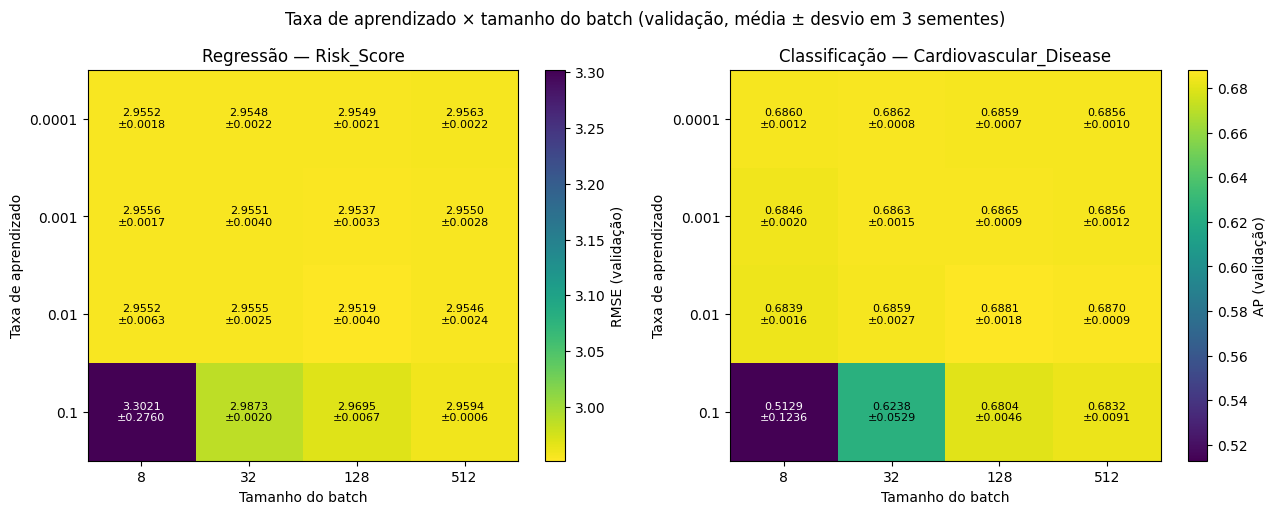


CUSTO E CONVERGÊNCIA — Regressão — Risk_Score (tempo apenas no processador de referência)


Taxa,Batch,Validação — média,Validação — desvio,Época do melhor estado — média,Épocas no limite (200),Tempo (s) — média,Sementes divergentes
0.0001,8,2.9552,0.0018,28.3333,0,95.4922,0
0.0001,32,2.9548,0.0022,68.0000,0,52.7519,0
0.0001,128,2.9549,0.0021,119.6667,1,35.0027,0
0.0001,512,2.9563,0.0022,171.3333,1,33.9667,0
0.001,8,2.9556,0.0017,16.6667,0,73.0103,0
0.001,32,2.9551,0.0040,17.6667,0,22.6258,0
0.001,128,2.9537,0.0033,31.6667,0,12.6041,0
0.001,512,2.9550,0.0028,37.0000,0,8.7881,0
0.01,8,2.9552,0.0063,12.0000,0,62.0677,0
0.01,32,2.9555,0.0025,17.6667,0,22.7269,0



CUSTO E CONVERGÊNCIA — Classificação — Cardiovascular_Disease (tempo apenas no processador de referência)


Taxa,Batch,Validação — média,Validação — desvio,Época do melhor estado — média,Épocas no limite (200),Tempo (s) — média,Sementes divergentes
0.0001,8,0.6860,0.0012,32.0000,0,100.1199,0
0.0001,32,0.6862,0.0008,67.6667,0,55.5709,0
0.0001,128,0.6859,0.0007,145.6667,1,41.7749,0
0.0001,512,0.6856,0.0010,187.6667,2,38.6573,0
0.001,8,0.6846,0.0020,8.6667,0,57.9939,0
0.001,32,0.6863,0.0015,12.6667,0,19.8879,0
0.001,128,0.6865,0.0009,13.0000,0,7.5107,0
0.001,512,0.6856,0.0012,35.3333,0,8.2786,0
0.01,8,0.6839,0.0016,11.6667,0,73.9550,0
0.01,32,0.6859,0.0027,18.6667,0,23.3325,0


In [25]:
execucoes_mapa = [(p, {"lr": lr, "batch_size": b}, SEMENTES_MAPA)
                  for p in ("regressao", "classificacao") for lr in LR_MAPA for b in BATCH_MAPA]
log = executar_bloco(execucoes_mapa, "mapa lr×batch")

def linhas_cfg(log, problema, extra, sementes):
    cid = treino.id_configuracao(treino.config_completa(extra))
    l = log[(log["problema"] == problema) & (log["config_id"] == cid) & log["semente"].isin(sementes)]
    assert len(l) == len(sementes), (problema, extra)
    return l

paineis_mapa, linhas_custo = [], []
for problema in ("regressao", "classificacao"):
    m = METRICA[problema]
    media = np.full((len(LR_MAPA), len(BATCH_MAPA)), np.nan)
    desvio = np.full_like(media, np.nan)
    for i, lr in enumerate(LR_MAPA):
        for j, b in enumerate(BATCH_MAPA):
            l = linhas_cfg(log, problema, {"lr": lr, "batch_size": b}, SEMENTES_MAPA)
            media[i, j], desvio[i, j] = l[f"{m}_validacao"].mean(), l[f"{m}_validacao"].std(ddof=1)
            mesmo_hw = l["dispositivo"] == PROCESSADOR_REFERENCIA
            linhas_custo.append({
                "Problema": problema, "Taxa": f"{lr:g}", "Batch": b,
                f"Validação — média": media[i, j], "Validação — desvio": desvio[i, j],
                "Época do melhor estado — média": l["epoca_melhor"].mean(),
                "Épocas no limite (200)": int((l["epocas_executadas"] >= 200).sum()),
                "Tempo (s) — média": l.loc[mesmo_hw, "tempo_s"].mean() if mesmo_hw.all() else np.nan,
                "Sementes divergentes": int(l["divergiu"].sum()),
            })
    paineis_mapa.append({"titulo": TITULO_PROBLEMA[problema], "matriz": media, "desvio": desvio,
                         "rotulo_metrica": NOME_METRICA[problema], "maior_melhor": MAIOR_MELHOR[problema]})

visualizacao.mapa_calor(paineis_mapa, [f"{lr:g}" for lr in LR_MAPA], [str(b) for b in BATCH_MAPA],
                        "Taxa de aprendizado × tamanho do batch (validação, média ± desvio em 3 sementes)",
                        "Taxa de aprendizado", "Tamanho do batch",
                        arquivo=pasta_figuras / "hiperparametros_mapa_lr_batch.png")

tabela_mapa = pd.DataFrame(linhas_custo)
for problema in ("regressao", "classificacao"):
    print(f"\nCUSTO E CONVERGÊNCIA — {TITULO_PROBLEMA[problema]} (tempo apenas no processador de referência)")
    display(tabela_mapa[tabela_mapa["Problema"] == problema].drop(columns="Problema")
            .style.format(precision=4, na_rep="—").hide(axis="index"))
tabela_mapa.to_csv(pasta_tabelas / "hiperparametros_mapa_lr_batch.csv", index=False,
                   encoding="utf-8-sig", float_format="%.16g")

**Análise — interação entre taxa de aprendizado e *batch*.**

**Evidência.** A interação aparece com clareza na taxa de $10^{-1}$: com *batch* 8, o desempenho colapsa nos dois problemas (RMSE médio próximo de 3,3 e AP próxima de 0,51, ambos com grande variação entre sementes); com *batch* 32, a degradação ainda é forte; com 128 e 512, o desempenho se aproxima do patamar das demais configurações (RMSE entre cerca de 2,96 e 2,97 e AP próxima de 0,68). No outro extremo, a taxa de $10^{-4}$ se torna lenta à medida que o *batch* cresce: a época do melhor estado passa de cerca de 30 (*batch* 8) para cerca de 170 a 190 (*batch* 512), com algumas sementes chegando ao limite de 200 épocas e desempenho ligeiramente inferior. A combinação de taxa $10^{-2}$ com *batch* 128 obteve a melhor média nos dois problemas (RMSE próximo de 2,952; AP próxima de 0,688), com treinamento de poucos segundos. Em todas as taxas, as células com *batch* 8 são as mais caras.

**Mecanismo.** O *batch* determina quantas atualizações ocorrem por época e quão ruidosa é a estimativa do gradiente. Com taxa alta, lotes pequenos combinam passos grandes com direções ruidosas e muitas atualizações por época, o que leva a rede a regiões ruins do espaço de parâmetros; lotes maiores estabilizam a direção do gradiente e reduzem o número de passos, tornando a mesma taxa tolerável. Com taxa baixa, ocorre o contrário: lotes grandes fazem poucas atualizações de tamanho pequeno, e o progresso por época se torna lento. Embora o Adam normalize a magnitude dos passos, a interação permanece visível, o que é compatível com o efeito do ruído na direção das atualizações e do número de atualizações por época.

**Conclusão prática.** Nestes dados, a taxa adequada cresce com o tamanho do *batch*: taxas de $10^{-3}$ a $10^{-2}$ com *batches* de 32 a 128 formam uma região estável e de baixo custo; a taxa de $10^{-1}$ só é tolerável com *batches* grandes, e *batches* pequenos devem ser evitados com taxas altas.

## 8. Busca aleatória

**Por que aleatória.** Com oito hiperparâmetros, a grade completa teria centenas de milhares de combinações. Quando apenas alguns hiperparâmetros têm efeito relevante — aqui, a taxa de aprendizado e os valores extremos —, uma busca aleatória de tamanho fixo cobre mais valores distintos de cada hiperparâmetro do que uma grade do mesmo tamanho (Bergstra e Bengio, 2012).

**Espaço.** Os valores sorteáveis são os mesmos dos estudos isolados, depois da triagem da Seção 4; o espaço é lido diretamente da tabela da triagem. O número de neurônios e o número de camadas são sorteados separadamente (todas as camadas com o mesmo número de neurônios). Os valores são discretos para que cada um tenha evidência própria nos estudos isolados, sem extrapolar para valores não testados.

**Sorteio.** Sorteio uniforme e independente em cada dimensão, com um único gerador `numpy.random.default_rng(42)`: primeiro as 25 configurações da regressão, depois as 25 da classificação (os espaços podem diferir pela triagem). Uma configuração repetida dentro da lista é sorteada de novo, até haver 25 distintas; uma configuração que coincida com outra já treinada nos estudos anteriores é aceita e reaproveitada pelo log. A lista é salva em `logs/busca_aleatoria_configuracoes.csv` antes de qualquer treinamento; em execuções posteriores, o sorteio é refeito e conferido com o arquivo salvo.

**Treinamento.** Sementes 0, 1 e 2.

In [26]:
N_POR_DIMENSAO = {"neuronios": "neurônios", "camadas": "camadas", "ativacao": "ativação",
                  "otimizador": "otimizador", "lr": "taxa", "batch": "batch",
                  "weight_decay": "weight decay", "dropout": "dropout"}

def espaco_busca(problema):
    t = tabela_exclusao[tabela_exclusao["Problema"] == problema]
    espaco, retirados = {}, []
    for chave in ESTUDOS:
        tc = t[t["chave"] == chave]
        espaco[chave] = list(tc.loc[~tc["Excluído da busca"], "valor_bruto"])
        for _, r in tc[tc["Excluído da busca"]].iterrows():
            retirados.append({"Problema": problema, "Hiperparâmetro": r["Hiperparâmetro"],
                              "Valor retirado": r["Valor"], "Motivo": r["Motivo"]})
    return espaco, retirados

def sortear_configuracoes(rng, espaco, n):
    lista, vistos = [], set()
    while len(lista) < n:
        cfg = {
            "hidden": (int(rng.choice(espaco["neuronios"])),) * int(rng.choice(espaco["camadas"])),
            "activation": str(rng.choice(espaco["ativacao"])),
            "otimizador": str(rng.choice(espaco["otimizador"])),
            "lr": float(rng.choice(espaco["lr"])),
            "batch_size": int(rng.choice(espaco["batch"])),
            "weight_decay": float(rng.choice(espaco["weight_decay"])),
            "dropout": float(rng.choice(espaco["dropout"])),
        }
        cid = treino.id_configuracao(treino.config_completa(cfg))
        if cid not in vistos:
            vistos.add(cid)
            lista.append((cid, cfg))
    return lista

rng = np.random.default_rng(42)
BUSCA, linhas_espaco, linhas_lista = {}, [], []
for problema in ("regressao", "classificacao"):
    espaco, retirados = espaco_busca(problema)
    linhas_espaco += retirados
    BUSCA[problema] = sortear_configuracoes(rng, espaco, N_BUSCA)
    for k, (cid, cfg) in enumerate(BUSCA[problema], start=1):
        linhas_lista.append({"problema": problema, "ordem": k, "config_id": cid,
                             "ja_treinada_antes": cid in ids_isolados or cid in ids_mapa,
                             **{c: (str(list(v)) if c == "hidden" else v) for c, v in cfg.items()}})
    print(f"Espaço — {TITULO_PROBLEMA[problema]}:")
    for chave, valores in espaco.items():
        print(f"  {ESTUDOS[chave]['nome']}: {[rotulo_valor(chave, v) for v in valores]}")

print("\nValores retirados pela triagem:")
display(pd.DataFrame(linhas_espaco).style.hide(axis="index") if linhas_espaco else "nenhum")

lista_busca = pd.DataFrame(linhas_lista)
caminho_lista = pasta_logs / "busca_aleatoria_configuracoes.csv"
if caminho_lista.is_file():
    salva = pd.read_csv(caminho_lista)
    assert list(salva["config_id"]) == list(lista_busca["config_id"]), \
        "O sorteio difere da lista salva: o espaço ou o código de sorteio mudou."
    print("Lista de configurações conferida com o arquivo salvo.")
else:
    lista_busca.to_csv(caminho_lista, index=False, encoding="utf-8-sig")
    print("Lista de configurações salva em", caminho_lista.relative_to(PROJETO))
print("Configurações já treinadas antes (reaproveitadas):", int(lista_busca["ja_treinada_antes"].sum()))

Espaço — Regressão — Risk_Score:
  Neurônios por camada: ['2', '4', '8', '16', '32', '64', '128']
  Camadas ocultas: ['1', '2', '3', '5']
  Função de ativação: ['ReLU', 'LeakyReLU', 'Tanh', 'Sigmoid', 'GELU']
  Otimizador: ['SGD', 'SGD+momentum', 'RMSprop', 'Adam', 'AdamW']
  Taxa de aprendizado: ['0.0001', '0.001', '0.01', '0.1', '1']
  Tamanho do batch: ['8', '32', '128', '512', '12.800']
  Weight decay (L2): ['0', '1e-05', '0.0001', '0.001', '0.01']
  Dropout: ['0.0', '0.1', '0.3', '0.5']
Espaço — Classificação — Cardiovascular_Disease:
  Neurônios por camada: ['2', '4', '8', '16', '32', '64', '128']
  Camadas ocultas: ['1', '2', '3', '5']
  Função de ativação: ['ReLU', 'LeakyReLU', 'Tanh', 'Sigmoid', 'GELU']
  Otimizador: ['SGD', 'SGD+momentum', 'RMSprop', 'Adam', 'AdamW']
  Taxa de aprendizado: ['0.0001', '0.001', '0.01', '0.1']
  Tamanho do batch: ['8', '32', '128', '512', '12.800']
  Weight decay (L2): ['0', '1e-05', '0.0001', '0.001', '0.01']
  Dropout: ['0.0', '0.1', '0.3', '0

Problema,Hiperparâmetro,Valor retirado,Motivo
classificacao,Taxa de aprendizado,1,não superou a referência ingênua em nenhuma semente


Lista de configurações conferida com o arquivo salvo.
Configurações já treinadas antes (reaproveitadas): 0


In [27]:
execucoes_busca = [(p, cfg, SEMENTES_BUSCA) for p in ("regressao", "classificacao") for _, cfg in BUSCA[p]]
log = executar_bloco(execucoes_busca, "busca aleatória")

linhas_res = []
for problema in ("regressao", "classificacao"):
    m = METRICA[problema]
    for k, (cid, cfg) in enumerate(BUSCA[problema], start=1):
        l = log[(log["problema"] == problema) & (log["config_id"] == cid) & log["semente"].isin(SEMENTES_BUSCA)]
        linhas_res.append({"Problema": problema, "Ordem": k, "Configuração": descrever(cfg),
                           "Parâmetros": int(l["n_parametros"].iloc[0]),
                           "Validação — média": l[f"{m}_validacao"].mean(),
                           "Validação — desvio": l[f"{m}_validacao"].std(ddof=1),
                           "Época do melhor estado — média": l["epoca_melhor"].mean(),
                           "Sementes divergentes": int(l["divergiu"].sum())})
tabela_busca = pd.DataFrame(linhas_res)
for problema in ("regressao", "classificacao"):
    t = tabela_busca[tabela_busca["Problema"] == problema].sort_values(
        "Validação — média", ascending=not MAIOR_MELHOR[problema])
    print(f"\nBUSCA ALEATÓRIA — {TITULO_PROBLEMA[problema]} ({NOME_METRICA[problema]} de validação, sementes 0 a 2)")
    display(t.drop(columns="Problema").style.format(precision=4, na_rep="—").hide(axis="index"))
tabela_busca.to_csv(pasta_tabelas / "hiperparametros_busca_aleatoria.csv", index=False,
                    encoding="utf-8-sig", float_format="%.16g")

busca aleatória: 0 execuções pendentes de 150

BUSCA ALEATÓRIA — Regressão — Risk_Score (RMSE de validação, sementes 0 a 2)


Ordem,Configuração,Parâmetros,Validação — média,Validação — desvio,Época do melhor estado — média,Sementes divergentes
4,"3×64 Tanh, AdamW, lr=0.01, batch=128, wd=0.0001, dropout=0",8833,2.9476,0.0050,20.6667,0
15,"2×16 Tanh, RMSprop, lr=0.0001, batch=8, wd=1e-05, dropout=0",401,2.9534,0.0030,100.0000,0
22,"1×8 ReLU, SGD, lr=0.1, batch=512, wd=0.001, dropout=0.1",65,2.9632,0.0035,69.3333,0
11,"2×128 ReLU, AdamW, lr=0.1, batch=512, wd=0, dropout=0.1",17537,2.9655,0.0099,27.0000,0
10,"1×16 Sigmoid, RMSprop, lr=0.001, batch=32, wd=0.0001, dropout=0.3",129,2.9697,0.0017,112.3333,0
17,"3×32 Tanh, RMSprop, lr=0.0001, batch=128, wd=0.001, dropout=0.1",2369,2.9712,0.0014,195.0000,0
20,"2×128 Tanh, Adam, lr=0.0001, batch=128, wd=0.0001, dropout=0.5",17537,2.9716,0.0010,196.3333,0
3,"1×16 GELU, RMSprop, lr=0.01, batch=32, wd=0, dropout=0.5",129,2.9717,0.0003,11.3333,0
25,"2×32 GELU, SGD, lr=0.001, batch=8, wd=1e-05, dropout=0.5",1313,2.9791,0.0096,123.6667,0
9,"2×8 GELU, SGD_momentum, lr=0.0001, batch=128, wd=0.001, dropout=0",137,2.9815,0.0090,200.0000,0



BUSCA ALEATÓRIA — Classificação — Cardiovascular_Disease (AP de validação, sementes 0 a 2)


Ordem,Configuração,Parâmetros,Validação — média,Validação — desvio,Época do melhor estado — média,Sementes divergentes
19,"2×128 GELU, AdamW, lr=0.0001, batch=8, wd=0.0001, dropout=0",17537,0.6886,0.0004,10.0000,0
16,"1×8 Sigmoid, AdamW, lr=0.1, batch=32, wd=1e-05, dropout=0",65,0.6883,0.0045,10.0000,0
7,"1×64 ReLU, RMSprop, lr=0.0001, batch=32, wd=0.001, dropout=0",513,0.6878,0.0007,141.0000,0
12,"2×16 GELU, SGD_momentum, lr=0.1, batch=32, wd=0.0001, dropout=0.3",401,0.6874,0.0023,15.6667,0
18,"2×128 LeakyReLU, AdamW, lr=0.01, batch=32, wd=0.001, dropout=0.3",17537,0.6871,0.0017,29.3333,0
14,"1×16 LeakyReLU, RMSprop, lr=0.001, batch=8, wd=0.001, dropout=0.3",129,0.6869,0.0004,33.3333,0
9,"3×128 Tanh, SGD_momentum, lr=0.01, batch=128, wd=1e-05, dropout=0",34049,0.6869,0.0011,54.0000,0
1,"5×8 Tanh, Adam, lr=0.001, batch=32, wd=0.001, dropout=0.5",353,0.6860,0.0006,28.3333,0
21,"5×64 LeakyReLU, AdamW, lr=0.0001, batch=128, wd=0.0001, dropout=0.1",17153,0.6858,0.0011,56.3333,0
10,"5×4 Tanh, RMSprop, lr=0.001, batch=512, wd=0, dropout=0",113,0.6857,0.0008,135.0000,0


**Análise — busca aleatória.**

**Evidência.** Com o sorteio uniforme, uma parte considerável das configurações caiu em regiões que os estudos isolados já indicavam como frágeis. Na regressão, a maioria das configurações com taxa igual a 1 (mantida no espaço pela triagem) teve desempenho ruim, e duas delas divergiram em todas as sementes. Na classificação, quatro configurações que combinavam o lote completo com passos pequenos (SGD com taxa de $10^{-3}$ ou taxa de $10^{-4}$) resultaram em AP abaixo da prevalência, isto é, redes que praticamente não foram treinadas nas 200 atualizações disponíveis; uma configuração com *weight decay* $10^{-2}$ produziu saída constante. Entre as configurações viáveis, o desempenho voltou ao mesmo patamar dos estudos isolados. A busca também mostrou interações que o estudo isolado não podia revelar: o SGD com momentum e taxa de $10^{-1}$, inviável para o Adam, alcançou AP no patamar das melhores configurações.

**Otimismo da validação na prática.** A melhor configuração sorteada na regressão teve média de validação claramente melhor nas três primeiras sementes do que nas cinco; na classificação, uma das finalistas perdeu boa parte da vantagem quando avaliada nas sementes 3 e 4. É o comportamento esperado quando se escolhe o máximo entre muitas médias ruidosas: parte da vantagem observada se deve ao acaso.

**Conclusão prática.** A busca não encontrou combinações que superem de forma relevante as melhores configurações dos estudos isolados, o que reforça a hipótese de que o desempenho está limitado pela informação contida nas seis features. Ela é útil, porém, para confirmar interações (otimizador × taxa, taxa × *batch*) e para mostrar que a amplitude do espaço tem custo: muitas execuções foram gastas em regiões instáveis, consequência direta da opção de não podar valores fracos.

## 9. Escolha da configuração final

**Candidatas.** Competem todas as configurações avaliadas na validação: as dos estudos isolados (incluindo a referência), as do mapa de calor e as da busca aleatória. A comparação inicial usa a média de validação nas sementes 0, 1 e 2, que todas as candidatas possuem. Configurações com divergência em qualquer semente disponível não são elegíveis.

**Finalistas e confirmação.** As cinco melhores candidatas elegíveis são as finalistas. As que ainda não têm as sementes 3 e 4 são treinadas com elas; uma finalista que divirja nessa confirmação é retirada.

A seleção ocorre, portanto, em **duas etapas**: (1) triagem de todas as candidatas pela média nas sementes 0, 1 e 2, que define as cinco finalistas; (2) decisão entre as finalistas confirmadas, com as cinco sementes. A regra de decisão escolhe apenas entre essas finalistas, e não entre todas as configurações possíveis.

**Regra de decisão.** A célula abaixo aplica primeiro a regra de parcimônia definida na Seção 1.1. Como mostrado na Seção 9.1, essa regra apresentou um defeito ao ser aplicada, e a decisão final usa uma regra revisada **depois** de observados os resultados da confirmação.

**Otimismo da validação.** Como muitas configurações são comparadas no mesmo subconjunto de validação, a melhor média observada tende a ser otimista: a configuração vencedora foi, em parte, favorecida por flutuações dessa amostra. A validação orienta a **escolha**; a estimativa do desempenho do modelo final é obtida no conjunto de teste, consultado uma única vez, depois do congelamento do modelo (Notebooks 06 e 07).

In [28]:
log = treino.carregar_log(CAMINHO_LOG)
ORIGINAL, rastros, tabelas_finalistas = {}, [], {}
POR_SEMENTE, ESTAVEIS, CONFIGS = {}, {}, {}

for problema in ("regressao", "classificacao"):
    m, maior = f"{METRICA[problema]}_validacao", MAIOR_MELHOR[problema]
    lp = log[log["problema"] == problema]
    # Divergências em todas as sementes disponíveis; média e contagem nas sementes 0, 1 e 2
    resumo = lp.groupby("config_id").agg(divergentes=("divergiu", "sum"), n_parametros=("n_parametros", "first"))
    base = lp[lp["semente"].isin(SEMENTES_MAPA)].groupby("config_id")
    resumo["media_012"] = base[m].mean()
    resumo["n_sementes_012"] = base["semente"].nunique()
    candidatas = resumo[(resumo["n_sementes_012"] == 3) & (resumo["divergentes"] == 0) & resumo["media_012"].notna()]
    finalistas = candidatas.sort_values(["media_012", "n_parametros"], ascending=[not maior, True]).head(N_FINALISTAS)

    # Confirmação: sementes 3 e 4 para as finalistas que ainda não as têm
    configs = {cid: config_da_linha(lp[lp["config_id"] == cid].iloc[0]) for cid in finalistas.index}
    log = executar_bloco([(problema, configs[cid], SEMENTES_CONFIRMACAO) for cid in finalistas.index],
                         f"confirmação ({problema})")
    lp = log[log["problema"] == problema]
    por_semente = {cid: lp[lp["config_id"] == cid].set_index("semente").sort_index()
                   for cid in finalistas.index}
    estaveis = [cid for cid in finalistas.index
                if por_semente[cid].loc[list(SEMENTES_ESTUDO), "divergiu"].sum() == 0]

    tab = pd.DataFrame([{
        "config_id": cid, "Configuração": descrever(configs[cid]), "Parâmetros": int(finalistas.loc[cid, "n_parametros"]),
        "Média sementes 0–2": finalistas.loc[cid, "media_012"],
        "Média 5 sementes": por_semente[cid].loc[list(SEMENTES_ESTUDO), m].mean(),
        "Desvio 5 sementes": por_semente[cid].loc[list(SEMENTES_ESTUDO), m].std(ddof=1),
        "Estável nas 5 sementes": cid in estaveis,
    } for cid in finalistas.index])
    tabelas_finalistas[problema] = tab
    print(f"\nFINALISTAS — {TITULO_PROBLEMA[problema]} ({NOME_METRICA[problema]} de validação)")
    display(tab.drop(columns="config_id").style.format(precision=4).hide(axis="index"))

    # Regra de parcimônia operacional (Seção 1.1)
    t = tab[tab["Estável nas 5 sementes"]].set_index("config_id")
    POR_SEMENTE[problema], ESTAVEIS[problema], CONFIGS[problema] = por_semente, t, configs
    ordem = t.sort_values(["Média 5 sementes", "Parâmetros"], ascending=[not maior, True]).index.tolist()
    C = ordem[0]
    while True:
        mais_simples = t[t["Parâmetros"] < t.loc[C, "Parâmetros"]].copy()
        mais_simples = mais_simples.sort_values(["Parâmetros", "Média 5 sementes"], ascending=[True, not maior])
        troca = None
        for S in mais_simples.index:
            vc = por_semente[C].loc[list(SEMENTES_ESTUDO), m]
            vs = por_semente[S].loc[list(SEMENTES_ESTUDO), m]
            d = (vc - vs) if maior else (vs - vc)          # positivo quando C é melhor
            claramente = bool((d > 0).sum() >= 4 and d.mean() > d.std(ddof=1))
            rastros.append({"Problema": problema, "C (escolhida provisória)": descrever(configs[C]),
                            "S (mais simples)": descrever(configs[S]),
                            "Parâmetros C / S": f"{int(t.loc[C, 'Parâmetros'])} / {int(t.loc[S, 'Parâmetros'])}",
                            "Sementes em que C é melhor": int((d > 0).sum()),
                            "Diferença média": d.mean(), "Desvio das diferenças": d.std(ddof=1),
                            "C claramente melhor": claramente})
            if not claramente:
                troca = S
                break
        if troca is None:
            break
        C = troca
    motivo = "melhor média de validação" if C == ordem[0] else "troca por configuração mais simples"
    ORIGINAL[problema] = {"config_id": C, "descricao": descrever(configs[C]), "motivo": motivo}
    print(f"Regra original (Seção 1.1) — escolheria: {descrever(configs[C])} ({motivo})")

tabela_rastro = pd.DataFrame(rastros)
print("\nCOMPARAÇÕES DA REGRA ORIGINAL (diagnóstico)")
display(tabela_rastro.style.format(precision=4).hide(axis="index") if len(tabela_rastro) else "nenhuma comparação necessária")

pd.concat([t.assign(Problema=p) for p, t in tabelas_finalistas.items()]).to_csv(
    pasta_tabelas / "hiperparametros_finalistas.csv", index=False, encoding="utf-8-sig", float_format="%.16g")
tabela_rastro.to_csv(pasta_tabelas / "hiperparametros_parcimonia_regra_original.csv",
                     index=False, encoding="utf-8-sig", float_format="%.16g")

confirmação (regressao): 0 execuções pendentes de 10

FINALISTAS — Regressão — Risk_Score (RMSE de validação)


Configuração,Parâmetros,Média sementes 0–2,Média 5 sementes,Desvio 5 sementes,Estável nas 5 sementes
"3×64 Tanh, AdamW, lr=0.01, batch=128, wd=0.0001, dropout=0",8833,2.9476,2.9507,0.0066,True
"2×32 ReLU, Adam, lr=0.01, batch=128, wd=0, dropout=0",1313,2.9519,2.9531,0.0039,True
"2×32 ReLU, Adam, lr=0.001, batch=32, wd=0.001, dropout=0",1313,2.9529,2.9518,0.0027,True
"2×32 LeakyReLU, Adam, lr=0.001, batch=32, wd=0, dropout=0",1313,2.9531,2.9531,0.0021,True
"2×32 ReLU, Adam, lr=0.001, batch=32, wd=0, dropout=0.1",1313,2.9532,2.9533,0.0016,True


Regra original (Seção 1.1) — escolheria: 2×32 ReLU, Adam, lr=0.001, batch=32, wd=0.001, dropout=0 (troca por configuração mais simples)
confirmação (classificacao): 0 execuções pendentes de 10

FINALISTAS — Classificação — Cardiovascular_Disease (AP de validação)


Configuração,Parâmetros,Média sementes 0–2,Média 5 sementes,Desvio 5 sementes,Estável nas 5 sementes
"2×128 GELU, AdamW, lr=0.0001, batch=8, wd=0.0001, dropout=0",17537,0.6886,0.6886,0.0009,True
"1×8 Sigmoid, AdamW, lr=0.1, batch=32, wd=1e-05, dropout=0",65,0.6883,0.6856,0.0056,True
"2×32 ReLU, Adam, lr=0.01, batch=128, wd=0, dropout=0",1313,0.6881,0.6871,0.0019,True
"1×64 ReLU, RMSprop, lr=0.0001, batch=32, wd=0.001, dropout=0",513,0.6878,0.6881,0.0007,True
"2×32 ReLU, Adam, lr=0.001, batch=32, wd=0.001, dropout=0",1313,0.6877,0.6882,0.0013,True


Regra original (Seção 1.1) — escolheria: 1×8 Sigmoid, AdamW, lr=0.1, batch=32, wd=1e-05, dropout=0 (troca por configuração mais simples)

COMPARAÇÕES DA REGRA ORIGINAL (diagnóstico)


Problema,C (escolhida provisória),S (mais simples),Parâmetros C / S,Sementes em que C é melhor,Diferença média,Desvio das diferenças,C claramente melhor
regressao,"3×64 Tanh, AdamW, lr=0.01, batch=128, wd=0.0001, dropout=0","2×32 ReLU, Adam, lr=0.001, batch=32, wd=0.001, dropout=0",8833 / 1313,3,0.0011,0.0091,False
classificacao,"2×128 GELU, AdamW, lr=0.0001, batch=8, wd=0.0001, dropout=0","1×8 Sigmoid, AdamW, lr=0.1, batch=32, wd=1e-05, dropout=0",17537 / 65,3,0.0030,0.0058,False


### 9.1 Defeito da regra original e regra revisada

**Diagnóstico.** Na classificação, a regra original escolheria a finalista com a **pior** média de validação nas cinco sementes e com o **maior** desvio entre sementes — uma configuração com taxa de aprendizado $10^{-1}$, região que os estudos isolados mostraram ser instável. A causa está no próprio critério: a configuração provisória só é mantida se for "claramente melhor" que a mais simples, isto é, se a diferença média pareada superar o desvio das diferenças. Quando a configuração mais simples é **instável**, o desvio das diferenças fica grande e o critério deixa de ser satisfeito justamente por causa dessa instabilidade. A regra, assim, favorece configurações simples e instáveis, o oposto do que um critério de parcimônia deve fazer; além disso, ela não exige que a configuração simples tenha desempenho próximo ao da melhor.

**Regra revisada.** Este defeito só foi identificado depois de observados os resultados da confirmação; a regra abaixo foi definida **após** essa observação e não é apresentada como pré-definida. Trata-se de uma **regra operacional inspirada na regra de um erro-padrão** usada em seleção de modelos:

1. Calcula-se o erro-padrão da média da melhor finalista: desvio entre as cinco sementes dividido por $\sqrt{5}$.
2. São aceitáveis as finalistas cuja média de validação esteja a até um erro-padrão da média da melhor.
3. Entre as aceitáveis, escolhe-se a de **menos parâmetros**; empates no número de parâmetros são desfeitos pela melhor média.

Diferentemente da regra original, ela compara cada finalista com a faixa de desempenho da melhor, e a instabilidade de uma configuração não decide o desempate. Não se trata da aplicação formal da regra de um erro-padrão: aqui, o erro-padrão é calculado entre cinco sementes e representa a variação entre inicializações e ordens de lotes, e não a incerteza devida à amostra de validação. O conjunto de teste não participou de nenhuma etapa desta decisão.

In [29]:
FINAL, linhas_revisada = {}, []
for problema in ("regressao", "classificacao"):
    maior, t, configs = MAIOR_MELHOR[problema], ESTAVEIS[problema], CONFIGS[problema]
    melhor = t.sort_values(["Média 5 sementes", "Parâmetros"], ascending=[not maior, True]).index[0]
    erro_padrao = t.loc[melhor, "Desvio 5 sementes"] / np.sqrt(len(SEMENTES_ESTUDO))
    media_melhor = t.loc[melhor, "Média 5 sementes"]
    limite = media_melhor - erro_padrao if maior else media_melhor + erro_padrao
    aceitavel = (t["Média 5 sementes"] >= limite) if maior else (t["Média 5 sementes"] <= limite)
    escolhida = t[aceitavel].sort_values(["Parâmetros", "Média 5 sementes"], ascending=[True, not maior]).index[0]
    for cid in t.index:
        linhas_revisada.append({"Problema": problema, "Configuração": descrever(configs[cid]),
                                "Parâmetros": int(t.loc[cid, "Parâmetros"]),
                                "Média 5 sementes": t.loc[cid, "Média 5 sementes"],
                                "Desvio 5 sementes": t.loc[cid, "Desvio 5 sementes"],
                                "Dentro de 1 erro-padrão da melhor": bool(aceitavel[cid]),
                                "Melhor média": cid == melhor, "Escolhida": cid == escolhida})
    FINAL[problema] = {
        "config_id": escolhida,
        "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in configs[escolhida].items()},
        "descricao": descrever(configs[escolhida]), "n_parametros": int(t.loc[escolhida, "Parâmetros"]),
        "metrica_validacao": NOME_METRICA[problema],
        "media_5_sementes": float(t.loc[escolhida, "Média 5 sementes"]),
        "desvio_5_sementes": float(t.loc[escolhida, "Desvio 5 sementes"]),
        "regra": "operacional inspirada na regra de um erro-padrão (revisada após a confirmação)",
        "erro_padrao_melhor": float(erro_padrao), "limite_aceitavel": float(limite),
        "melhor_media": descrever(configs[melhor]),
        "escolha_pela_regra_original": ORIGINAL[problema]["descricao"],
    }
    print(f"{TITULO_PROBLEMA[problema]}: limite aceitável {NOME_METRICA[problema]} "
          f"{'≥' if maior else '≤'} {limite:.4f} (melhor {media_melhor:.4f}, erro-padrão {erro_padrao:.4f})")
    print(f"  Escolhida: {descrever(configs[escolhida])}")
    print(f"  Regra original escolheria: {ORIGINAL[problema]['descricao']}")

tabela_revisada = pd.DataFrame(linhas_revisada)
print("\nREGRA REVISADA — FINALISTAS CONFIRMADAS")
display(tabela_revisada.style.format(precision=4).hide(axis="index"))
tabela_revisada.to_csv(pasta_tabelas / "hiperparametros_escolha_final.csv", index=False,
                       encoding="utf-8-sig", float_format="%.16g")

import json
with open(pasta_logs / "configuracao_final.json", "w", encoding="utf-8") as f:
    json.dump(FINAL, f, ensure_ascii=False, indent=2)
print("\nConfiguração final salva em", (pasta_logs / "configuracao_final.json").relative_to(PROJETO))

Regressão — Risk_Score: limite aceitável RMSE ≤ 2.9536 (melhor 2.9507, erro-padrão 0.0030)
  Escolhida: 2×32 ReLU, Adam, lr=0.001, batch=32, wd=0.001, dropout=0
  Regra original escolheria: 2×32 ReLU, Adam, lr=0.001, batch=32, wd=0.001, dropout=0
Classificação — Cardiovascular_Disease: limite aceitável AP ≥ 0.6882 (melhor 0.6886, erro-padrão 0.0004)
  Escolhida: 2×32 ReLU, Adam, lr=0.001, batch=32, wd=0.001, dropout=0
  Regra original escolheria: 1×8 Sigmoid, AdamW, lr=0.1, batch=32, wd=1e-05, dropout=0

REGRA REVISADA — FINALISTAS CONFIRMADAS


Problema,Configuração,Parâmetros,Média 5 sementes,Desvio 5 sementes,Dentro de 1 erro-padrão da melhor,Melhor média,Escolhida
regressao,"3×64 Tanh, AdamW, lr=0.01, batch=128, wd=0.0001, dropout=0",8833,2.9507,0.0066,True,True,False
regressao,"2×32 ReLU, Adam, lr=0.01, batch=128, wd=0, dropout=0",1313,2.9531,0.0039,True,False,False
regressao,"2×32 ReLU, Adam, lr=0.001, batch=32, wd=0.001, dropout=0",1313,2.9518,0.0027,True,False,True
regressao,"2×32 LeakyReLU, Adam, lr=0.001, batch=32, wd=0, dropout=0",1313,2.9531,0.0021,True,False,False
regressao,"2×32 ReLU, Adam, lr=0.001, batch=32, wd=0, dropout=0.1",1313,2.9533,0.0016,True,False,False
classificacao,"2×128 GELU, AdamW, lr=0.0001, batch=8, wd=0.0001, dropout=0",17537,0.6886,0.0009,True,True,False
classificacao,"1×8 Sigmoid, AdamW, lr=0.1, batch=32, wd=1e-05, dropout=0",65,0.6856,0.0056,False,False,False
classificacao,"2×32 ReLU, Adam, lr=0.01, batch=128, wd=0, dropout=0",1313,0.6871,0.0019,False,False,False
classificacao,"1×64 ReLU, RMSprop, lr=0.0001, batch=32, wd=0.001, dropout=0",513,0.6881,0.0007,False,False,False
classificacao,"2×32 ReLU, Adam, lr=0.001, batch=32, wd=0.001, dropout=0",1313,0.6882,0.0013,True,False,True



Configuração final salva em logs/configuracao_final.json


**Análise — configuração final.**

A regra revisada seleciona, nos dois problemas, a **mesma configuração**: 2 camadas ocultas de 32 neurônios, ReLU, Adam com taxa de aprendizado $10^{-3}$, *batch* de 32, sem *dropout* e com *weight decay* de $10^{-3}$ — isto é, a configuração de referência acrescida de regularização L2 leve. Na regressão, ela também é a escolha da regra original; na classificação, substitui a configuração instável escolhida pela regra original.

A escolha é coerente com os estudos isolados, nos quais o *weight decay* de $10^{-3}$ já havia produzido a melhor média de validação nos dois problemas. A diferença em relação à configuração de referência é, contudo, pequena — da ordem da variação entre sementes —, e não deve ser interpretada como uma melhora demonstrada: a configuração final é, essencialmente, a referência com uma regularização leve, escolhida por estar entre as melhores e ser estável e de custo baixo.

Como todas as decisões deste notebook foram tomadas no mesmo subconjunto de validação, as médias de validação da configuração escolhida tendem a ser otimistas. O desempenho do modelo final é estimado no conjunto de teste, consultado uma única vez, depois do congelamento do modelo (Notebooks 06 e 07).

In [30]:
# Contagem efetiva de treinamentos registrados no log (comparada ao máximo nominal)
log = treino.carregar_log(CAMINHO_LOG)
print("Treinamentos registrados no log:", len(log), "| máximo nominal previsto:", TOTAL_TREINOS)
print("Por problema:", log.groupby("problema").size().to_dict())
print("Processadores registrados:", log["dispositivo"].value_counts().to_dict())

Treinamentos registrados no log: 546 | máximo nominal previsto: 554
Por problema: {'classificacao': 275, 'regressao': 271}
Processadores registrados: {'cpu (Intel(R) Xeon(R) CPU @ 2.20GHz)': 546}
